# Cuprins

- [1. Distribuția t](#sec-1)
   - [1.1. Un pas foarte important](#sec-1-1)
- [2. Compararea a două medii. Criteriul t Student](#sec-2)
   - [2.1. Exemple](#sec-2-1)
      - [2.1.1. Problema 1](#sec-2-1-1)
      - [2.1.2. Problema 2](#sec-2-1-2)
- [3. Analiza dispersională unifactorială](#sec-3)
   - [3.1. Problemă](#sec-3-1)
   - [3.2. Câteva despre notațiile din analiza dispersională](#sec-3-2)
   - [3.3. Problemă](#sec-3-3)
- [4. Noțiunea de corelație](#sec-4)
   - [4.1. Covarianța și corelația](#sec-4-1)
   - [4.2. Corelația și determinația](#sec-4-2)
   - [4.3. Exemplu](#sec-4-3)
   - [4.4. Probleme](#sec-4-4)
      - [4.4.1. Problema 1](#sec-4-4-1)
      - [4.4.2. Problema 2](#sec-4-4-2)
      - [4.4.3. Problema 3](#sec-4-4-3)
- [5. Regresia cu o singură variabilă independentă](#sec-5)
   - [5.1. Metoda celor mai mici pătrate](#sec-5-1)
- [6. Ipoteza despre semnificația legăturii și coeficientul de determinație](#sec-6)
   - [6.1. Coeficientul de determinație](#sec-6-1)
   - [6.2. Problemă](#sec-6-2)
- [7. Condițiile de aplicare a regresiei liniare cu un singur predictor](#sec-7)
- [8. Aplicarea analizei de regresie și interpretarea rezultatelor](#sec-8)
   - [8.1. Problemă](#sec-8-1)
- [9. Problema prognozării valorilor variabilei dependente](#sec-9)
   - [9.1. Observații](#sec-9-1)
- [10. Analiza de regresie cu mai multe variabile independente](#sec-10)
   - [10.1. Cerințe față de date](#sec-10-1)
- [11. Alegerea celui mai bun model](#sec-11)
   - [11.1. Alegerea modelului](#sec-11-1)
   - [11.2. Observații](#sec-11-2)
- [12. Clasificarea: regresia logistică și analiza cluster](#sec-12)
   - [12.1. Regresia logistică](#sec-12-1)
      - [12.1.1. Exemplu](#sec-12-1-1)
   - [12.2. Analiza cluster](#sec-12-2)

In [1]:
'''Importăm bibliotecile necesare pentru lucru'''
%matplotlib inline

# Modul standard Python >= 3.4 pentru calculul statisticii matematice a datelor numerice.
# Orientat spre nivelul calculatoarelor grafice și științifice.
import statistics
# Modulul standard implementează generatoare de numere pseudoaleatoare pentru diverse distribuții
from random import randint
import random as r

# Modulul standard oferă acces la funcțiile matematice definite de standardul C.
import math

# Bibliotecă ce adaugă suport pentru tablouri și matrice multidimensionale mari, împreună
# cu o bibliotecă vastă de funcții matematice de nivel înalt (și foarte rapide) pentru operații cu aceste tablouri.
import numpy as np
from numpy import random
# Bibliotecă open source bazată pe NumPy pentru calcule științifice și inginerești.
from scipy import (
    stats, ndimage)

# Bibliotecă pentru prelucrarea și analiza datelor, cu NumPy „sub capotă”.
import pandas as pd

# Biblioteca oferă un set de metode de testare și modelare statistică, precum și
# instrumente destinate analizei seriilor de timp (acestea pot fi folosite și pentru prognozare).
import statsmodels.api as sm

from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import (
    pairwise_tukeyhsd, MultiComparison)
from statsmodels.graphics.factorplots import interaction_plot

# Bibliotecă pentru vizualizarea datelor 2D, precum și a graficelor 3D.
import matplotlib.pyplot as plt
# API de nivel mai înalt, bazat pe biblioteca matplotlib.
import seaborn as sns
# Pentru construirea graficelor 3D
from mpl_toolkits.mplot3d import Axes3D

# 1. Distribuția t<a id="sec-1" name="sec-1"></a>

<center><img src="../slides/week_2/week_2-02.png" title="slide 2" width="50%" height="50%"/></center>

`Distribuția Student` (*t-distribution*) reprezintă, în esență, suma mai multor variabile aleatoare distribuite normal. Cu cât sunt mai multe variabile, cu atât este mai mare probabilitatea ca suma lor să aibă o distribuție normală.
Astfel, numărul variabilelor însumate determină cel mai important parametru de formă al acestei distribuții — numărul gradelor de libertate (*degrees of freedom* $df=n-1$).


<center><img src="../imgs/t_test.png" title="T test" width="75%" height="75%"/></center>

Diagrama este preluată din cartea „Statistica pentru cei care (cred că) urăsc statistica”.

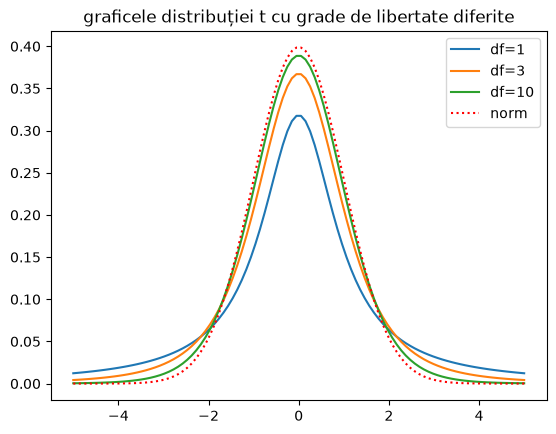

In [2]:
'''
Graficul de mai jos arată cum se schimbă forma distribuției la creșterea numărului de grade de libertate.
De asemenea, arată apropierea distribuției t de cea normală pe măsură ce crește numărul gradelor de libertate.
'''
x = np.linspace(-5, 5, 100)
y1, y2, y3 = stats.t.pdf(x, df=1), stats.t.pdf(x, df=3), stats.t.pdf(x, df=10)
y4 = stats.norm.pdf(x)

plt.title('graficele distribuției t cu grade de libertate diferite')
plt.plot(x, y1)
plt.plot(x, y2)
plt.plot(x, y3)
plt.plot(x, y4, 'r:')
plt.legend(('df=1', 'df=3', 'df=10', 'norm'))
plt.show()

Graficul densității distribuției Student, ca și cel al distribuției normale, este simetric și are formă de clopot, dar cu „cozi” mai „grele”.

## 1.1. Un pas foarte important<a id="sec-1-1" name="sec-1-1"></a>

În prelegerile video am spus că folosim distribuția t în situația unui volum mic al eșantionului. Este necesar să explicăm mai detaliat de ce este nevoie de aceasta.

Să revenim la teorema limită centrală. Am aflat deja că, dacă o anumită caracteristică în populația statistică este distribuită normal ([nu neapărat](https://stepik.org/lesson/8077/step/7?unit=1357)) cu media $\mu$ și abaterea standard $\sigma$, iar noi vom extrage de multe ori eșantioane de aceeași mărime $n$ și pentru fiecare eșantion vom calcula cât de departe s-a abătut media de eșantion $\bar{X}$ de la media populației statistice, în unități ale erorii standard a mediei:

$$\large z = \frac{\bar{X} - \mu}{\frac{\sigma}{\sqrt{n}}}$$

atunci această mărime $\large z$ va avea o distribuție normală standard, cu media egală cu zero și abaterea standard egală cu unu.

Atrageți atenția că pentru calculul erorii standard folosim anume abaterea standard din populația statistică — $\sigma$. Am discutat deja că în practică $\sigma$ nu ne este aproape niciodată cunoscută, iar pentru calculul erorii standard folosim abaterea standard de eșantion.

Așadar, strict vorbind, în acest caz distribuția abaterii mediei de eșantion de la media populației statistice, împărțită la eroarea standard, va fi descrisă anume cu ajutorul distribuției t:

$$\large t = \frac{\bar{X} - \mu}{\frac{sd}{\sqrt{n}}}$$

astfel, în cazul unei $\sigma$ necunoscute **vom avea întotdeauna de-a face cu distribuția t.**

În acest moment ar trebui să mă întrebați indignați: de ce atunci am aplicat criteriul z în primul modul al cursului, pentru verificarea ipotezelor, folosind abaterea standard de eșantion?

Știm deja că, la un volum suficient de mare al eșantionului (de obicei în manuale se dă regula $n > 30$), distribuția t se apropie foarte mult de distribuția normală:

De aceea uneori, pentru simplitatea calculelor, se spune că dacă n > 30, vom folosi proprietățile distribuției normale în scopurile noastre. Strict vorbind, aceasta este, desigur, o abordare incorectă, care este adesea criticată. În epoca dinaintea calculatoarelor exista o anumită explicație: pentru a nu calcula pentru fiecare n mai mare de 30 valoarea critică corespunzătoare a distribuției t, statisticienii parcă rotunjeau rezultatul și foloseau în acest scop distribuția normală. Astăzi, desigur, nu mai există nicio problemă cu aceasta, iar toate programele statistice vor calcula fără efort toți indicatorii necesari pentru distribuția t cu orice număr de grade de libertate. Într-adevăr, la eșantioane de volum foarte mare distribuția t practic nu se va deosebi de cea normală, însă diferențe, deși foarte mici, tot vor exista.

De aceea, mai corect ar fi să spunem că folosim distribuția t nu pentru că avem eșantioane mici, ci pentru că nu cunoaștem abaterea standard din populația statistică.

Prin urmare, în continuare vom folosi întotdeauna distribuția t pentru verificarea ipotezelor, dacă nu cunoaștem abaterea standard din populația statistică, necesară pentru calculul erorii standard, chiar dacă volumul eșantionului este mai mare de 30.

Teze suplimentare:

- **Folosirea distribuției t micșorează probabilitatea de a comite o eroare de tipul I, adică de a respinge ipoteza nulă atunci când ea este adevărată.**

- **Numărul gradelor de libertate este diferența dintre numărul observațiilor și numărul parametrilor estimați.**

[Articol](https://habr.com/ru/company/stepic/blog/311354/) pe Habr despre gradele de libertate (în limba rusă).

In [3]:
'''Exemplu
Pe un eșantion de 15 observații, cu ajutorul testului t pentru un singur eșantion, se verifică ipoteza nulă:
mu=10, iar valoarea t calculată este egală cu -2 (t = -2); atunci nivelul de semnificație p (bilateral) este egal cu:
'''
t = -2
n = 15
df = n - 1

p = 2 * stats.t.sf(abs(t), df)
print("p = {:.3f}".format(p))

p = 0.065


# 2. Compararea a două medii. Criteriul t Student<a id="sec-2" name="sec-2"></a>

`Criteriul t Student` este denumirea generală a testelor statistice în care statistica criteriului are distribuția Student. Cel mai des criteriile t se aplică pentru verificarea egalității valorilor medii în două eșantioane. Ipoteza nulă presupune că mediile sunt egale (negarea acestei presupuneri se numește ipoteza deplasării). Pentru aplicarea acestui criteriu este necesar ca datele inițiale să aibă o distribuție normală.

$$ t = \frac{\bar{X_1} - \bar{X_2}}{se}$$

$$ se = \sqrt{\frac{sd_1^2}{n_1} + \frac{sd_2^2}{n_2}} $$

De unde provine această formulă pentru $se$?

$$ (se_1)^2 = (\frac{sd_1}{\sqrt{n_1}})^2 = \frac{sd_1^2}{n_1} $$

Adică:

$$ se = \sqrt{\frac{sd_1^2}{n_1} + \frac{sd_2^2}{n_2}} = \sqrt{se_1^2 + se_2^2} $$

iar răspunsul la întrebarea de ce este adevărată această egalitate se ascunde în proprietatea dispersiei: dispersia sumei unor variabile aleatoare independente este egală cu suma dispersiilor lor, iar abaterea este rădăcina pătrată din dispersie. De aici rezultă ultima formulă.

## 2.1. Exemple<a id="sec-2-1" name="sec-2-1"></a>

Cel mai des criteriul Student se aplică pentru verificarea egalității valorilor medii în două eșantioane.

**Exemplul 1**.
- Primul eșantion — pacienții tratați cu preparatul A.
- Al doilea eșantion — pacienții tratați cu preparatul B.
- Valorile din eșantioane — o anumită caracteristică a eficienței tratamentului (nivelul unui metabolit în sânge, temperatura la trei zile după începerea tratamentului, durata vindecării, numărul de zile de spitalizare etc.)
- Trebuie să aflăm dacă există o diferență semnificativă între eficiența preparatelor A și B sau dacă diferențele sunt pur întâmplătoare și se explică prin dispersia „naturală” a caracteristicii alese.

**Exemplul 2**.
- Primul eșantion — valorile unei anumite caracteristici a stării pacienților, înregistrate înainte de tratament.
- Al doilea eșantion — valorile aceleiași caracteristici a stării acelorași pacienți, înregistrate după tratament.
- Volumele ambelor eșantioane trebuie să coincidă; mai mult, ordinea elementelor (în acest caz a pacienților) în eșantioane trebuie de asemenea să coincidă. Astfel de eșantioane se numesc `dependente` (perechi).
- Trebuie să aflăm dacă există o diferență semnificativă în starea pacienților înainte și după tratament sau dacă diferențele sunt pur întâmplătoare.

**Exemplul 3**.
- Primul eșantion — câmpurile prelucrate prin metoda agrotehnică A.
- Al doilea eșantion — câmpurile prelucrate prin metoda agrotehnică B.
- Valorile din eșantioane — recolta.
- Trebuie să aflăm dacă una dintre metode este mai eficientă decât cealaltă sau dacă diferențele de recoltă se datorează unor factori întâmplători.

**Exemplul 4**.
- Primul eșantion — zilele în care în supermarket a avut loc o promoție de tipul A (etichete roșii cu reducere).
- Al doilea eșantion — zilele promoției de tipul B (fiecare al cincilea pachet gratuit).
- Valorile din eșantioane — un indicator al eficienței promoției (volumul vânzărilor sau încasările în lei).
- Trebuie să aflăm care tip de promoție este mai eficient.

### 2.1.1. Problema 1<a id="sec-2-1-1" name="sec-2-1-1"></a>

In [4]:
'''
Ipoteza nulă: media temperaturii de topire a tipului 1 = media temperaturii de topire a tipului 2
Ipoteza alternativă: am obținut rezultate valoroase, iar media tipului 1 <> media tipului 2
'''
array1 = np.array([84.7, 105.0, 98.9, 97.9, 108.7, 81.3, 99.4, 89.4, 93.0,
                   119.3, 99.2, 99.4, 97.1, 112.4, 99.8, 94.7, 114.0, 95.1, 115.5, 111.5])
array2 = np.array([57.2, 68.6, 104.4, 95.1, 89.9, 70.8, 83.5, 60.1, 75.7,
                   102.0, 69.0, 79.6, 68.9, 98.6, 76.0, 74.8, 56.0, 55.6, 69.4, 59.5])

# calculăm numărul de elemente, media, abaterea standard și eroarea standard
df = pd.DataFrame({'Eșantionul1':array1, 'Eșantionul2':array2}).agg(['mean','std','count','sem']).transpose()
df.columns = ['Mx','SD','N','SE']

# calculăm intervalul de 95% al abaterii mediei
# K — jumătatea intervalului (în unități relative față de abaterea standard) în care se află p (în acest caz 95%)
# din toate valorile pentru distribuția Student cu gradul de libertate corespunzător.
# Doar că aici este o greșeală — în loc de 'Mx' trebuie 'N'.
# A doua linie adaugă încă o coloană (intervalele de încredere propriu-zise, deja în unități absolute) în dataframe-ul inițial df.
p = 0.95
K = stats.t.ppf((1 + p)/2, df['N']-1)
df['interval'] = K * df['SE']

df

,Mx,SD,N,SE,interval
Eșantionul1,100.815,10.246503,20.0,2.291188,4.795511
Eșantionul2,75.735,15.458102,20.0,3.456537,7.234614


C:\Temp\ipykernel_33016\2914705288.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bplot1 = ax1.boxplot([array1, array2],
C:\Temp\ipykernel_33016\2914705288.py:11: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  bplot2 = ax2.errorbar(x=df.index, y=df['Mx'], yerr=df['interval'],\


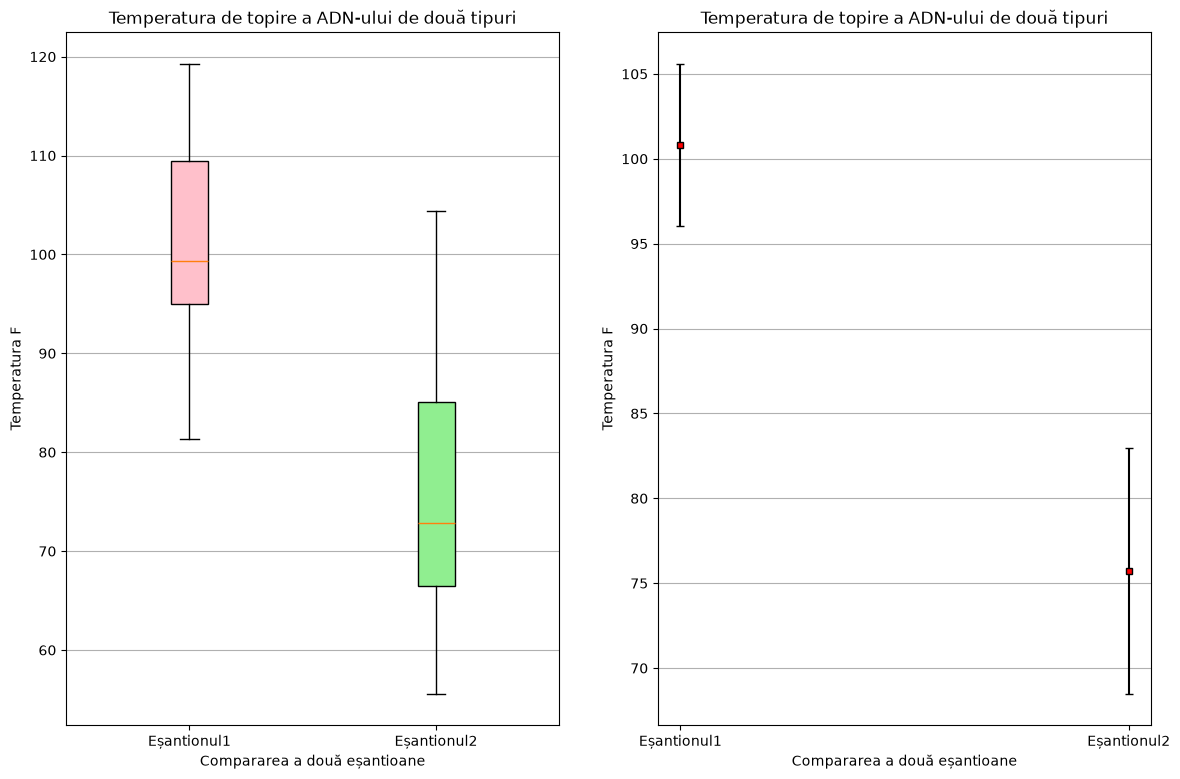

In [5]:
# construim graficele: boxplot din datele inițiale array1, array2 și intervalele de încredere din dataframe-ul df
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 9))

# graficul boxplot
bplot1 = ax1.boxplot([array1, array2],
                     vert=True,  # creăm cutii verticale
                     patch_artist=True, # pentru frumusețe colorăm cutiile cuantilelor
                     tick_labels=['Eșantionul1', 'Eșantionul2']) # se folosește pentru denumirile eșantioanelor în cazul boxplot

# graficul intervalelor de încredere
bplot2 = ax2.errorbar(x=df.index, y=df['Mx'], yerr=df['interval'],\
                      color="black", capsize=3, marker="s", markersize=4, mfc="red", mec="black", fmt ='o')

# colorăm boxplot-ul
colors = ['pink', 'lightgreen']
for patch, color in zip(bplot1['boxes'], colors):
    patch.set_facecolor(color)

# adăugăm elementele comune pentru fiecare dintre grafice
for ax in [ax1, ax2]:
    ax.yaxis.grid(True)
    ax.set_title('Temperatura de topire a ADN-ului de două tipuri')
    ax.set_xlabel('Compararea a două eșantioane')
    ax.set_ylabel('Temperatura F')

plt.show()

### 2.1.2. Problema 2<a id="sec-2-1-2" name="sec-2-1-2"></a>

În primul experiment, pentru compararea a două medii $\bar{X_{1}}=17$ și $\bar{X_{2}}=16$ s-a aplicat criteriul t Student, iar aceste diferențe s-au dovedit semnificative ($p = 0,001$).
În al doilea studiu, tot cu ajutorul criteriului t, s-au comparat două medii $\bar{X_{1}}=17$ și $\bar{X_{2}}=36$, iar aceste diferențe nu sunt semnificative, $p = 0,8$. Care poate fi cauza unor astfel de rezultate?

**Soluție**:
- $(x1-x2)\uparrow$ $ \Rightarrow $ $t \uparrow$ (cu cât este mai mare diferența dintre mediile eșantioanelor, cu atât este mai mare criteriul t)
- $sd \downarrow$ $ \Rightarrow $ $t \uparrow$
- $n \uparrow$ $ \Rightarrow $ $t \uparrow$
- $t \uparrow$ $ \Rightarrow $ $p \downarrow$

Prin urmare, posibil că în primul experiment volumul eșantioanelor este mai mare, iar variabilitatea caracteristicii studiate este mai mică.

# 3. Analiza dispersională unifactorială<a id="sec-3" name="sec-3"></a>

Un [articol](https://r-analytics.blogspot.com/2013/01/blog-post.html) bun despre analiza dispersională (în limba rusă).

Aceasta este continuarea temei comparării mediilor în eșantioane. Doar că acum grupurile pe care le comparăm nu sunt două, ci mai multe. Criteriul t Student (la fel ca analogii săi neparametrici) permite compararea **doar a două grupuri**, iar analiza dispersională unifactorială (*One Way ANalysis Of VAriance*, *ANOVA*) — a 2 sau mai multe.

Variabila care va împărți subiecții sau observațiile noastre în grupuri (o variabilă nominală cu mai multe gradații) se numește `variabilă independentă`. Iar variabila cantitativă după gradul de exprimare a căreia comparăm grupurile se numește `variabilă dependentă`.

$$ SS_{total} = \sum_{j=1}^{p}{\sum_{i=1}^{n_j}{(x_{ij} - \bar{x})^2}} = SS_{between} + SS_{within} $$
$$ SS_{between} = \sum_{j=1}^{p}{n_j{(\bar{x}_j - \bar{x})^2}} $$
$$ SS_{within} = \sum_{j=1}^{p}{\sum_{i=1}^{n_j}{(x_{ij} - \bar{x}_j)^2}} $$

Distribuția teoretică a valorii F în analiza dispersională nu este normală, ci se supune `distribuției Fisher` (F distribution).

În cartea „Statistics Unplugged” a autoarei Sally Caldwell este descris în mod intuitiv mersul raționamentului.

<center><img src="../imgs/ANOVA_1.png" title="ANOVA 1 slide" width="50%" height="50%"/></center>

<center><img src="../imgs/ANOVA_2.png" title="ANOVA 2 slide" width="50%" height="50%"/></center>

<center><img src="../imgs/ANOVA_3.png" title="ANOVA 3 slide" width="75%" height="75%"/></center>

<center><img src="../imgs/ANOVA_4.png" title="ANOVA 4 slide" width="50%" height="50%"/></center>

<center><img src="../imgs/ANOVA_5.png" title="ANOVA 5 slide" width="75%" height="75%"/></center>

<center><img src="../imgs/ANOVA_6.png" title="ANOVA 6 slide" width="50%" height="50%"/></center>

Ipoteza nulă: a=b=c
Ipoteza alternativă: !(a=b=c)
p=0.008000000000000002 , Rezultat: respingem ipoteza nulă


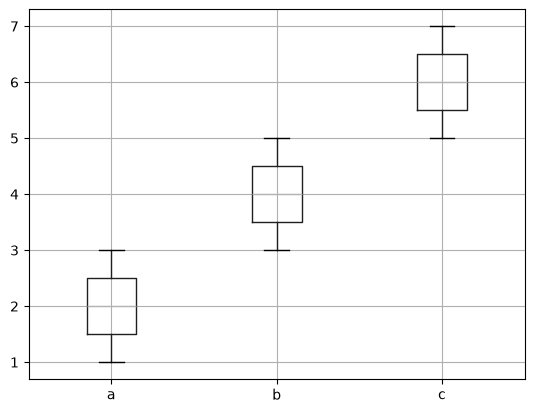

In [6]:
# Eșantioanele care trebuie comparate
data = pd.DataFrame({
           'a': [3, 1, 2],
           'b': [5, 3, 4],
           'c': [7, 6, 5]
          })
data.boxplot()

print('Ipoteza nulă:', '='.join(data))
print('Ipoteza alternativă:', f'!({"=".join(data)})')

# media generală
grand_mean = data.values.flatten().mean()
# abaterea mediilor de grup de la media generală
ssb = sum(data[group].size * (group_mean - grand_mean)**2  for group, group_mean in data.mean().items())
# abaterile valorilor din interiorul grupului de la media grupului
ssw = sum(sum((x - group_mean)**2 for x in data[group]) for group, group_mean in data.mean().items())

groups = data.shape[1]
dfb = groups - 1
dfw = data.size - groups
# pătratul mediu intergrupal
mssb = ssb/dfb
# pătratul mediu intragrupal
mssw = ssw/dfw

f_value = mssb/mssw

p = stats.f.sf(f_value, dfb, dfw)

print("p={} , Rezultat: {}".format(
    p,
    "respingem ipoteza nulă" if p < 0.05 else "NU respingem ipoteza nulă"
))

## 3.1. Problemă<a id="sec-3-1" name="sec-3-1"></a>

Să presupunem că, la compararea a patru grupuri între ele (câte 5 observații în fiecare grup), ați obținut F = 3.5. Acceptăm sau respingem ipoteza nulă despre egalitatea mediilor?

**Soluție:**
Presupunem că ipoteza nulă $H_{0}$ este adevărată și că toate cele 4 eșantioane (câte 5 observații în fiecare) sunt extrase din aceeași populație statistică. Trebuie să estimăm în câte cazuri, dintr-o mulțime de experimente de extragere aleatoare a 4 grupuri de câte 5 valori, vom obține o astfel de valoare F (un astfel de raport între diferențele dintre grupuri și din interiorul grupurilor — SSB/SSW).

Numărul gradelor de libertate ($df_{SSB}$) pentru suma pătratelor intergrupale ($SSB$) va fi egal cu $(n_{\text{grupuri}} - 1) = 4 - 1 = 3$.
Numărul gradelor de libertate ($df_{SSW}$) pentru suma pătratelor din interiorul grupurilor ($SSW$) va fi egal cu $(n_{\text{grupuri}} * (n_{\text{elemente în fiecare grup}}-1))$ sau $(N_{\text{total observații}} - n_{\text{grupuri}}) = 4 * (5-1) = 16$.

Introducând aceste valori ($df_{SSB} \rightarrow  df-1$ și $df_{SSW} \rightarrow  df-2$) în [calculator](https://gallery.shinyapps.io/dist_calc/) (definind forma curbei F) și valoarea F obținută (a), obținem probabilitatea de a obține o astfel de valoare la repetări multiple ale experimentului (Probability-value):
<center><img src="../imgs/ex_2.png" title="Distribution calculator" width="75%" height="75%"/></center>

Dacă valoarea **P**_robability-value va fi mai mică de 5%, ipoteza că lucrăm cu aceeași populație statistică va trebui respinsă; dacă este mai mare — acceptată!

**De reținut:**
$$F = \frac{\frac{ssb}{ssb_{deg}}}{\frac{ssw}{ssw_{deg}}}$$
$$df_{1} = ssb_{deg} \;\;\;\;\;\; df_{2} = ssw_{deg}$$


In [7]:
'''Soluția în Python'''
F = 3.5
df_ssb = 3
df_ssw = 16

print("{}".format(
    stats.f.sf(F, df_ssb, df_ssw)
))

0.040052541494826115


## 3.2. Câteva despre notațiile din analiza dispersională<a id="sec-3-2" name="sec-3-2"></a>

Când împărțim valoarea sumei pătratelor intergrupale la numărul corespunzător de grade de libertate (numărul de grupuri minus unu), facem astfel media indicatorului obținut. Valoarea medie a sumei pătratelor intergrupale se numește `pătratul mediu intergrupal`.

$$MS_{bg}=\frac{SSB}{df_{bg}} \;\;\;\;\;\; df_{bg}=m-1$$

Raportul dintre suma pătratelor intragrupale și numărul corespunzător de grade de libertate (numărul tuturor observațiilor minus numărul de grupuri) este `pătratul mediu intragrupal`.

$$MS_{wg}=\frac{SSW}{df_{wg}} \;\;\;\;\;\; df_{wg}=N-m$$

De aceea, formula valorii F (raportul F) se scrie adesea:
$$F=\frac{MS_{bg}}{MS_{wg}}$$

**Problemă teoretică**

- <font color="green">Cu cât este mai mare dispersia în interiorul grupurilor, cu atât este mai mare valoarea pătratului mediu intragrupal (la un număr neschimbat de observații)</font> — Să analizăm. Pătratul mediu intragrupal $MS_{wg}=\frac{SSW}{df_{wg}}$, unde
$SSW$ este suma abaterilor pătratice de la medie **în interiorul grupului;**
$df_{wg}=N-n_{\text{grupuri}}$ este numărul corespunzător de grade de libertate (numărul tuturor observațiilor minus numărul de grupuri).
Presupunând că numărul de grupuri și numărul total de observații nu se schimbă, se vor modifica doar dispersiile intragrupale ale fiecărui grup, deci și suma totală a pătratelor intragrupale (SSW), ceea ce va duce în mod inevitabil la creșterea pătratului mediu intragrupal (la creșterea SSW).

- <font color="green">Suma totală a pătratelor, împărțită la numărul tuturor observațiilor minus unu, este chiar dispersia calculată pentru toate observațiile noastre fără a ține cont de împărțirea în grupuri</font> — corect, deoarece exact așa se definește dispersia de eșantion (ne amintim că împărțim la numărul de observații din eșantion minus unu):
$$D_{sample}=\frac{\sum\limits_{i=1}^N (x_i - \bar X)^2}{N-1},$$
adică o astfel de dispersie, ca și cum am fi uitat de existența împărțirii observațiilor în grupuri și am fi lucrat cu ele ca și cu un singur eșantion.

- <font color="red">Cu cât este mai mare valoarea pătratului mediu intragrupal, cu atât este neapărat mai mare valoarea pătratului mediu intergrupal</font> — Este ușor de arătat că nu este așa: aceste valori nu depind una de alta, iar dacă ar depinde, sensul aplicării criteriului F ar dispărea de la sine.

- <font color="red">Cu cât este mai mică valoarea raportului F, cu atât sunt mai mari șansele de a respinge ipoteza nulă (la compararea a trei grupuri a câte 10 observații)</font> — Cu cât este mai mică valoarea criteriului F, la numere neschimbate care caracterizează grupurile comparate (numărul lor m și numărul total de observații N), cu atât este mai mare aria situată la dreapta valorii F, deci cu atât este mai mare valoarea nivelului de semnificație p. Apropo, la analiza graficului distribuției Fisher este important să ne amintim că probabilitatea p o calculăm doar în coada din dreapta, adică P(X>F), și că toate valorile F sunt întotdeauna pozitive.

- <font color="red">Cu ajutorul analizei dispersionale se pot compara între ele doar 2 grupuri</font> — Analiza dispersională permite compararea între ele nu doar a două grupuri, ci și a mai multor grupuri. Atrageți atenția chiar și asupra formulelor: ele sunt scrise pentru m grupuri și N observații.


## 3.3. Problemă<a id="sec-3-3" name="sec-3-3"></a>

Terapia genică permite corectarea funcționării unei gene defecte, responsabile de dezvoltarea bolii. În experiment s-a comparat eficiența a patru terapii diferite.

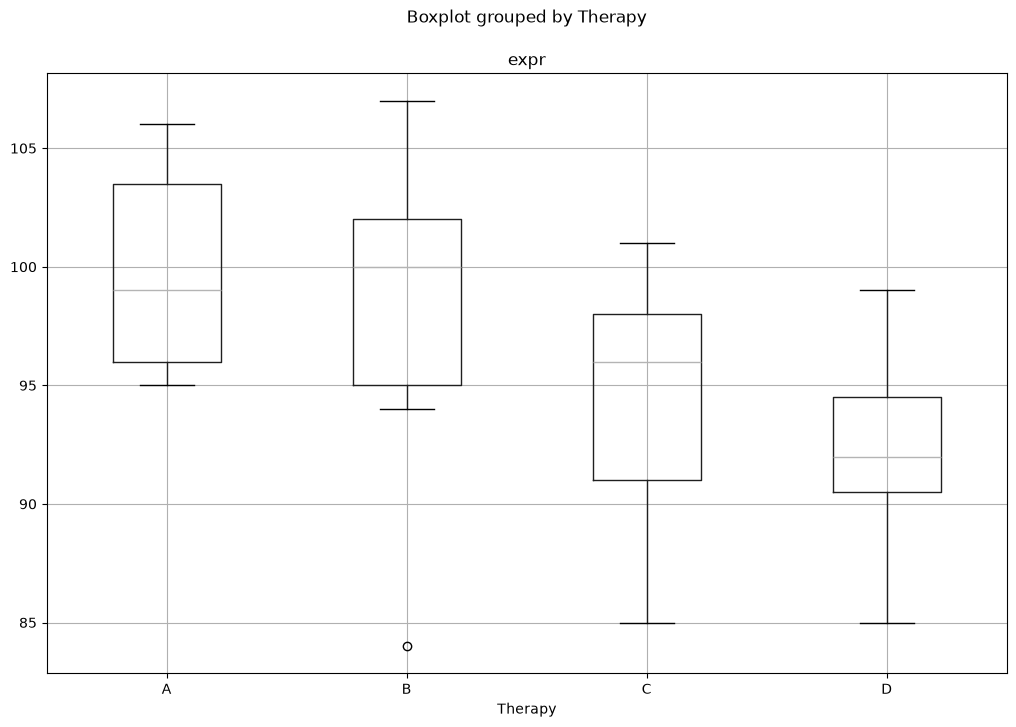

In [8]:
def ssw(main_data: pd.DataFrame, group_col: str, value_col: str):
    group_names = data[group_col].unique()
    return np.sum([
        (
            main_data.loc[main_data[group_col] == group, value_col] -
            main_data.loc[main_data[group_col] == group, value_col].mean()
        ) ** 2
        for group in group_names
    ])


def ssb(main_data: pd.DataFrame, group_col: str, value_col: str):
    group_names = data[group_col].unique()
    overall_mean = main_data[value_col].mean()
    return np.sum([
        len(main_data.loc[main_data[group_col] == group, value_col]) * (
            main_data.loc[main_data[group_col] == group, value_col].mean() -
            overall_mean
        ) ** 2
        for group in group_names
    ])


data = pd.read_csv('../data/genetherapy.csv')
groups = data['Therapy'].unique()
subsets = [data.query('Therapy == @group')['expr'] for group in groups]

pd_boxplot = data.boxplot('expr', by='Therapy', figsize=(12, 8), grid=True)

In [9]:
ssb_df = len(groups) - 1
ssw_df = data.shape[0] - len(groups)

SSW = ssw(data, 'Therapy', 'expr')
SSB = ssb(data, 'Therapy', 'expr')

# Metoda analizei dispersionale unifactoriale
f_val, p_val = stats.f_oneway(*subsets)

anova_results = pd.DataFrame([
{
        'Df': ssb_df,
        'Sum Sq': '{0:.2f}'.format(SSB),
        'Mean Sq': '{0:.2f}'.format(SSB / ssb_df),
        'F-value': '{0:.2f}'.format(f_val),
        'p-value': '{0:.4f}'.format(p_val),
    },
    {
        'Df': ssw_df,
        'Sum Sq': '{0:.2f}'.format(SSW),
        'Mean Sq': '{0:.2f}'.format(SSW / ssw_df),
        'F-value': '',
        'p-value': '',
    },
], index=['Therapy', 'Residuals'])

print(anova_results)

           Df   Sum Sq Mean Sq F-value p-value
Therapy     3   560.72  186.91    8.04  0.0002
Residuals  56  1302.27   23.25                


<center><img src="../slides/week_2/week_2-21.png" title="Slide 21" width="75%" height="75%"/></center>

**Variabila independentă** (VI) — tipul terapiei (Therapy), **variabila dependentă** (VD) — nivelul de expresie a genelor.

Acum să analizăm rezultatele analizei dispersionale.
Pentru VI sunt calculate numărul gradelor de libertate ($Df=m-1=4-1=3$) și suma pătratelor (Sum sq), adică SSB. Dacă împărțim $\frac{SSB}{df}=\text{Mean sq}$, obținem indicatorul mediu al sumei pătratelor intergrupale.
Drept reziduuri (Residuals) apare acea parte a variabilității care se manifestă în interiorul grupurilor (SSW). Pentru a ne convinge: $df=N-m=60-4=56$, unde N este numărul de observații, iar m este numărul de grupuri. Iar $\frac{SSW}{df}=23.25=\text{Mean sq}$.
Și cel mai interesant: valoarea F este raportul dintre variabilitatea intergrupală și cea intragrupală. Amintindu-ne cum arată distribuția Fisher, vedem că ne-am îndepărtat destul de mult de partea ei principală din stânga.
Valoarea p ne spune că o astfel de abatere am fi putut-o obține cu o probabilitate care ne permite cu încredere să respingem ipoteza nulă $H_{0}$. Aceasta ne spune că **cel puțin două medii diferă între ele (F(3,56)=8.04, p<0.05)**.

# 4. Noțiunea de corelație<a id="sec-4" name="sec-4"></a>
## 4.1. Covarianța și corelația<a id="sec-4-1" name="sec-4-1"></a>

`Covarianța` este o **măsură liniară** care arată gradul de variabilitate comună („în tandem”) a două variabile aleatoare.

$$ cov(X, Y) = \frac{\sum{(x_i - \bar{x})(y_i - \bar{y})}}{N - 1} $$
unde N este numărul de observații, iar unu este numărul gradelor de libertate pierdute.

Totuși, doar după valoarea **absolută** a covarianței nu putem judeca cât de puternic sunt legate variabilele, deoarece scara covarianței depinde de dispersiile lor.
Valoarea covarianței poate fi normalizată, împărțind-o la produsul abaterilor medii pătratice (rădăcinile pătrate din dispersii) ale variabilelor aleatoare (altfel spus, împărțind la ${\sigma_x\sigma_y}$, o aducem în intervalul [-1, 1]).

Mărimea obținută se numește `coeficientul de corelație Pearson`, care se află întotdeauna în intervalul de la −1 la 1:

$$ r(x, y) = \frac{cov(x, y)}{\sigma_x\sigma_y}$$

`Corelația` este un caz particular al covarianței, care poate fi obținut prin standardizarea datelor.
Când trebuie să alegem care este cea mai bună măsură a legăturii dintre două variabile, corelația este preferabilă covarianței, deoarece nu depinde de schimbarea poziției și a scării și poate fi folosită pentru comparații între două perechi de variabile.

[Sursa](https://ru.gadget-info.com/difference-between-covariance)  | CO-VARIANȚA | CO-RELAȚIA
------------- | ------------- | -----------
Definiție  | `Covarianța` este o **măsură liniară** care arată gradul de variabilitate comună a două variabile aleatoare  | `Corelația` este o **măsură statistică** care arată cât de puternic sunt legate două variabile.
Ce este?  | Măsură a legăturii  | Versiunea scalată a covarianței
Valori  | Între -∞ și + ∞  | Între -1 și +1
Schimbarea scării | Influențează covarianța  | Nu influențează corelația
Are unitate de măsură  | Da  | Nu



<center><img src="../slides/week_3/week_3-01.png" title="slide 1" width="50%" height="50%"/></center>

**Graficul 1:** o astfel de legătură se numește `negativă` sau `inversă` și corespunde unei corelații negative între două variabile.
**Graficul 2:** legătura pozitivă corespunde unei corelații pozitive.
**Graficul 3 (de jos):** diagrama de dispersie (scatter plot)

<center><img src="../slides/week_3/week_3-02.png" title="slide 2" width="50%" height="50%"/></center>

$\bar{X}$ roșu și $\bar{Y}$ albastru sunt valorile medii ale eșantionului. Întreaga diagramă de dispersie s-a împărțit prin aceste linii în 4 cadrane.
Dacă majoritatea valorilor se află în cadranul din dreapta sus (++) și în cel din stânga jos (--), aceasta înseamnă o legătură pozitivă.
Dacă valorile s-ar afla în cadranul din stânga sus (-+) și în cel din dreapta jos (+-), aceasta ar indica o legătură negativă.

## 4.2. Corelația și determinația<a id="sec-4-2" name="sec-4-2"></a>

<center><img src="../slides/week_3/week_3-06.png" title="slide 6" width="50%" height="50%"/></center>

<center><img src="../slides/week_3/week_3-07.png" title="slide 7" width="50%" height="50%"/></center>

Pătratul coeficientului de corelație se numește `coeficient de determinație`. „Influența” din definiție nu presupune o relație cauză–efect.
Coeficientul de determinație arată în ce măsură dispersia unei variabile este determinată de legătura cu cealaltă.
Deoarece este un pătrat, ia valori în intervalul $[0,1]$.

## 4.3. Exemplu<a id="sec-4-3" name="sec-4-3"></a>
Demonstrarea funcționării covarianței și a corelației

In [10]:
def cov(x, y):
    assert x.size == y.size
    return ((x - x.mean()) * (y - y.mean())).sum()/(x.size - 1)

def cor(x, y):
    return cov(x, y)/(np.std(x, ddof=1)*np.std(y, ddof=1))

# funcție care imită factorii întâmplători
# p — cât de important va fi factorul întâmplător
def randomize(arr, p):
    alpha = np.max(arr) - np.min(arr)
    res = np.zeros(arr.shape)
    for i, v in enumerate(arr):
        sign = 1 if r.choice([True, False]) else -1
        res[i] = v + sign*alpha*r.random()*p
    return res

In [11]:
x = np.array(range(30))
y = randomize(x, 0.1)
y1 = randomize(x, 0.5)
y2 = randomize(x, 1)

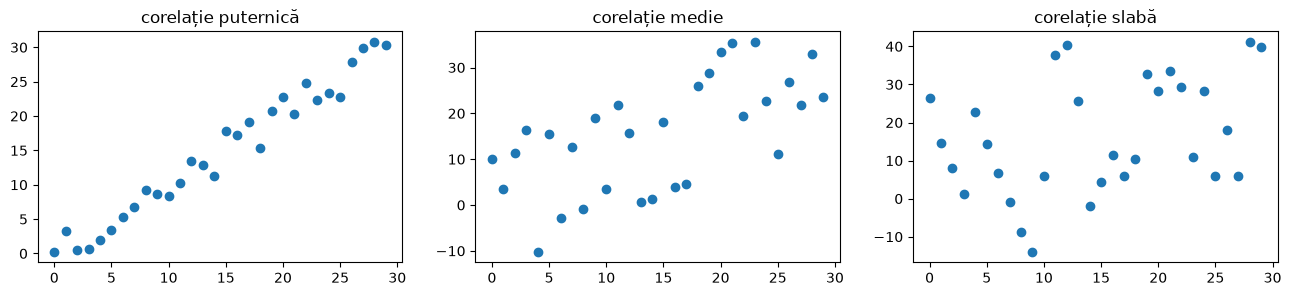

In [12]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 3))
ax1.scatter(x, y)
ax2.scatter(x, y1)
ax3.scatter(x, y2)
ax1.set_title('corelație puternică')
ax2.set_title('corelație medie')
ax3.set_title('corelație slabă')
plt.show()

In [13]:
print(f'''
cov1: {cov(x, y):.2f} and cor1: {cor(x, y):.2f}
cov2: {cov(x, y1):.2f} and cor2: {cor(x, y1):.2f}
cov3: {cov(x, y2):.2f} and cor3: {cor(x, y2):.2f}
''')


cov1: 83.40 and cor1: 0.98
cov2: 67.18 and cor2: 0.62
cov3: 47.17 and cor3: 0.35



## 4.4. Probleme<a id="sec-4-4" name="sec-4-4"></a>
### 4.4.1. Problema 1<a id="sec-4-4-1" name="sec-4-4-1"></a>

<center><img src="../imgs/ex_4.png" title="Exercise" width="75%" height="75%"/></center>

- A 0.02
- B 0.55
- C 0.9

### 4.4.2. Problema 2<a id="sec-4-4-2" name="sec-4-4-2"></a>

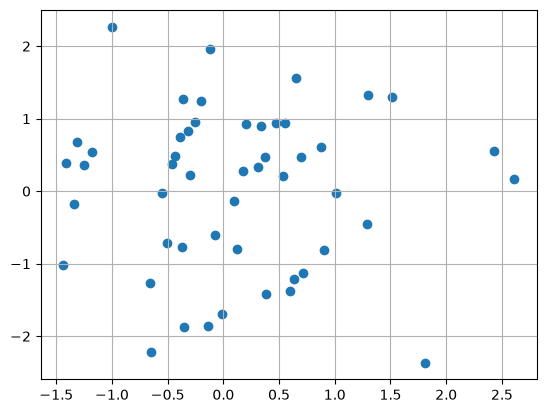

correlation: PearsonRResult(statistic=np.float64(-0.019214769861124414), pvalue=np.float64(0.8946326576071897))
data: x and y
t = 2.06697, df = 48, p-value = 0.04415
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
[0.00819306 0.52264617]
sample estimates:
cor
0.2858888


In [14]:
def cortest(corr, lenX):
    # valoarea t
    t = corr[0] * ((len(X) - 2) / (1 - corr[0]**2))**0.5
    print("data: x and y")
    print("t = {}, df = {}, p-value = {}".format(round(t,5), len(X)-2, round(stats.t.sf(np.abs(t), 48)*2,5)))

    # Folosim transformarea Fisher pentru a obține z
    z = np.arctanh(corr[0])
    #print("z value: {}".format(z))

    # Și valoarea sigma, adică eroarea standard
    sigma = (1/((len(X)-3)**0.5))
    #print("sigma value: {}".format(sigma))

    # Obținem intervalul de 95% pentru variabila aleatoare continuă normală
    # aplicăm formula bilaterală
    cint = z + np.array([-1, 1]) * sigma * stats.norm.ppf((1+0.95)/2)

    # La final aplicăm tangenta hiperbolică pentru a obține limitele intervalului de 95%
    interval = np.tanh(cint)

    if corr != 0:
        print("alternative hypothesis: true correlation is not equal to 0")
    print("95 percent confidence interval:")
    print(interval)
    print("sample estimates:")
    print("cor")
    print(corr[0])

# așa calculăm corelația
X = stats.norm.rvs(loc=0, scale=1, size=50)
Y = stats.norm.rvs(loc=0, scale=1, size=50)
corr = stats.pearsonr(X, Y)

# așa construim scatter plot-ul
plt.scatter(X,Y)
plt.grid()
plt.show()

print("correlation: {}".format(corr))

# deoarece din prelegere nu cunoaștem eșantioanele, introducem direct corelația din prelegere
cortest((0.2858888,), 50)

### 4.4.3. Problema 3<a id="sec-4-4-3" name="sec-4-4-3"></a>

Cu cât este egal coeficientul de corelație în acest eșantion (încercați să construiți graficul pentru a găsi răspunsul corect):
$$ X = \begin{bmatrix}4\\5\\2\\3\\1\end{bmatrix} \:\:\: Y = \begin{bmatrix}2\\1\\4\\3\\5\end{bmatrix}$$

In [15]:
'''Soluția în Python'''
X = [4,5,2,3,1]
Y = [2,1,4,3,5]

print("Pearson’s correlation coefficient: {}\nTwo-tailed p-value: {}".format(
    *stats.pearsonr(X,Y)
))

Pearson’s correlation coefficient: -1.0
Two-tailed p-value: 0.0


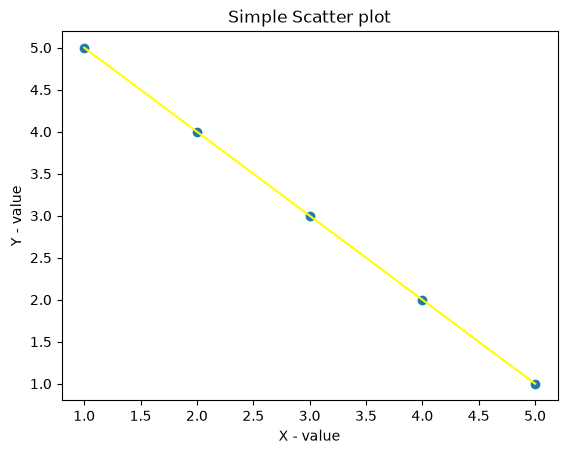

In [16]:
# Dreapta de regresie
plt.plot(np.unique(X), np.poly1d(np.polyfit(X, Y, 1))(np.unique(X)), color='yellow')

# Diagrama de dispersie a lui X și Y
plt.scatter(X, Y)
plt.rcParams.update({'figure.figsize':(3,3), 'figure.dpi':100})
plt.title('Simple Scatter plot')
plt.xlabel('X - value')
plt.ylabel('Y - value')
plt.show()

# 5. Regresia cu o singură variabilă independentă<a id="sec-5" name="sec-5"></a>

<center><img src="../slides/week_3/week_3-14.png" title="slide 14" width="50%" height="50%"/></center>

`Analiza de regresie` este un set de metode statistice de studiere a influenței uneia sau a mai multor variabile independente $X_{1}, X_{2} , ... , X_{p}$ asupra variabilei dependente $Y$.
Variabilele independente se mai numesc `regresori` sau `predictori`, iar variabilele dependente — `variabile criteriu`. Terminologia de variabile dependente și independente reflectă doar dependența matematică dintre variabile (vezi Corelația), și nu relații cauză–efect.
Cel mai răspândit tip de analiză de regresie este `regresia liniară` (*linear regression*), în care se caută funcția liniară care, conform anumitor criterii matematice, corespunde cel mai bine datelor.
De exemplu, în metoda celor mai mici pătrate se calculează dreapta (sau hiperplanul) pentru care suma pătratelor distanțelor dintre ea și date este minimă.

$$ y = b_0 + b_1x $$
$b_0$ (intercept) — valoarea în care dreapta intersectează axa Y
$b_1$ (slope) — stabilește panta dreptei de regresie

## 5.1. Metoda celor mai mici pătrate<a id="sec-5-1" name="sec-5-1"></a>

<center><img src="../slides/week_3/week_3-15.png" title="slide 15" width="75%" height="75%"/></center>

`Metoda celor mai mici pătrate` (MCMMP, *Least Squares*, *LS*) este o modalitate de a găsi parametrii optimi ai regresiei liniare ($b_0$, $b_1$), astfel încât suma pătratelor erorilor (reziduurilor) să fie minimă. Parametrii se calculează după formulele:
$$ b_0 = \bar{Y} - b_1\bar{X} \:\:, \:\: b_1 = \frac{sd_y}{sd_x}r_{xy}$$
unde $sd$ este abaterea standard, iar $r$ este coeficientul de corelație.

Esența MCMMP (obișnuite, clasice) constă în găsirea acelor parametri $b$ pentru care **suma pătratelor abaterilor** (**erorilor**; pentru modelele de regresie ele se numesc adesea **reziduuri ale regresiei**) $e_{t}$ va fi minimă.

b0=98.65167224331182
b1=1.0063961725851986


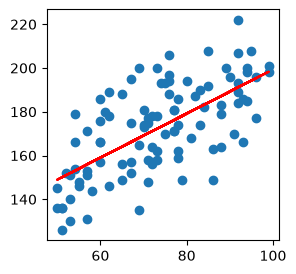

In [17]:
'''Demonstrarea MCMMP'''
N = 100

X = np.array([np.random.randint(50,100) for i in range(N)])
Y = np.array([i+np.random.randint(80,120)-np.random.randint(-20,20) for i in X])

plt.scatter(X, Y)
b1, b0 = np.polyfit(X, Y, 1) #  b0 - intercept, b1 - slope
plt.plot(X, b0 + b1*X, color='red')
print("b0={}\nb1={}".format(b0,b1))

# 6. Ipoteza despre semnificația legăturii și coeficientul de determinație<a id="sec-6" name="sec-6"></a>

<center><img src="../slides/week_3/week_3-16.png" title="slide 16" width="75%" height="75%"/></center>

Ce facem dacă vrem să răspundem la întrebarea: cât de semnificativă statistic este legătura dintre cele două variabile ale noastre?
Ipoteza nulă $H_0:b_1=0$, ipoteza alternativă $H_1:b_1 \ne 0$
$$t=\frac{b_1-0}{se}=\frac{b_1}{se} \:\:,\:\: df=N-2$$
**Ideea principală:** `criteriul t` verifică ipoteza că coeficientul nostru $b_1$, responsabil de panta dreptei, este diferit de zero în populația statistică.

## 6.1. Coeficientul de determinație<a id="sec-6-1" name="sec-6-1"></a>

<center><img src="../slides/week_3/week_3-17.png" title="slide 17" width="75%" height="75%"/></center>

$R^2$ este proporția din dispersia variabilei dependente ($Y$) explicată de modelul de regresie.
Pătratul coeficientului de corelație ($r$) al eșantionului se notează, de regulă, $R^2$ și se numește **coeficient de determinație**.

De exemplu, cum este determinată **calitatea** de **prețul** produsului nostru. Pe figura din stânga, cu albastru este reprezentată dreapta de regresie, care este doar foarte puțin înclinată în sus, deoarece coeficientul de corelație $r=0.04$ este prea mic. Și vrem să răspundem la întrebarea: **în ce măsură variabilitatea variabilei calitate se explică prin legătura cu variabila preț**?

$$R^2=1-\frac{SS_{res}}{SS_{total}}$$

$SS_{res}$ este suma pătratelor distanțelor de la observațiile noastre până la dreapta de regresie.

Pe figura din dreapta vedem o corelație pronunțată ($r=0.99 \rightarrow 1$). Punctele noastre sunt situate foarte aproape de dreapta de regresie, iar suma pătratelor reziduurilor ($SS_{res}$) va fi mult mai mică decât suma totală a pătratelor. Aceasta face ca raportul $\frac{SS_{res}}{SS_{total}}$ să devină tot mai mic (iar $R^2$ — tot mai mare) cu cât modelul nostru de regresie este mai bun.
În cazul nostru, $R^2 \approx 1$ ne spune că practic 100% din variabilitatea variabilei dependente ($Y$) este determinată de legătura ei cu variabila independentă ($X$). Adică modelul nostru de regresie explică și descrie foarte bine comportamentul și variabilitatea variabilei dependente ($Y$). De aceea, cu cât $R^2$ este mai mare, cu atât modelul nostru se descurcă mai bine cu sarcina pusă, și anume explică și prezice valorile variabilei dependente.

## 6.2. Problemă<a id="sec-6-2" name="sec-6-2"></a>

<font color="red">Dacă coeficientul de determinație este egal cu zero, atunci și coeficientul b0 (intercept) este egal cu zero.</font> — dacă $R^2=0$, grafic putem spune că dreapta de regresie este orizontală (perpendiculară pe axa $Y$). $b_0$ răspunde de valoarea în care dreapta intersectează axa Y. Dacă avem o variabilitate mare, este puțin probabil ca intersecția să fie în $Y=0$.

<font color="red">Coeficientul de determinație poate fi egal cu unu doar în cazul în care corelația dintre variabile este pozitivă și egală cu 1.</font> — „doar în cazul”: $R^2=1$ și atunci când $r=-1$.

<font color="green">Cu cât este mai mare coeficientul de determinație, cu atât o parte mai mare din dispersia variabilei dependente este determinată de legătura cu variabila independentă.</font> — strict vorbind, CD nu răspunde de creșterea dispersiei, ci indică proporția dispersiei explicate. Aceasta rezultă chiar din formula CD: CD = 1 − Suma pătratelor reziduurilor / Suma totală a pătratelor abaterilor. Deoarece suma totală a pătratelor abaterilor caracterizează cât de puternic se abate fiecare valoare Y de la media eșantionului, iar suma pătratelor reziduurilor arată ce parte din aceste abateri nu este explicată de ecuația de regresie obținută, a doua parte a formulei (Suma pătratelor reziduurilor / Suma totală a pătratelor abaterilor) ne dă, în esență, o idee despre ce proporție din dispersia lui Y nu este explicată de ecuația de regresie (din cauza faptului că valorile prognozate nu coincid cu cele reale). Dacă scădem proporția dispersiei neexplicate din 1, restul obținut este tocmai dispersia lui Y pe care o explică ecuația de regresie.

<font color="green">Dacă coeficientul de determinație este egal cu zero, atunci și coeficientul b1 (slope) este egal cu zero.</font> — din primul punct am înțeles cum se comportă $b_0$, iar $b_1$ răspunde de panta dreptei de regresie. Tocmai el va fi egal cu zero.

# 7. Condițiile de aplicare a regresiei liniare cu un singur predictor<a id="sec-7" name="sec-7"></a>

<center><img src="../slides/week_3/week_3-18.png" title="slide 18" width="50%" height="50%"/></center>

**Predictorul** (*predictor*, „cel care prezice”) este un parametru prognostic; un mijloc de prognozare.

1. Legătură liniară între $X$ și $Y$. Aici este evident: ce sens are să facem aceasta dacă variabilele sunt legate în mod neliniar.
2. Distribuția normală a reziduurilor.
3. Homoscedasticitatea — variabilitate constantă a reziduurilor la toate nivelurile variabilei independente.

Să folosim [serviciul](https://gallery.shinyapps.io/slr_diag/).

Suplimentar, din comentarii:
**Dreapta de corelație** arată direcția (pozitivă sau negativă) și „puterea” legăturii. Dar ea nu descrie pe deplin datele inițiale.
**Dreapta de regresie** descrie datele noastre, de aceea pe baza acestei drepte putem prezice și acele date care nu existau în setul inițial.

**De exemplu**: avem date despre prețul și suprafața apartamentelor dintr-un anumit cartier. Dreapta de corelație ne poate arăta legătura dintre suprafața apartamentului și prețul lui și, de exemplu, putem afla că, cu cât suprafața este mai mare, cu atât prețul este mai mare. Dar dacă ni s-ar cere să determinăm prețul unui anumit apartament, nu am putea face aceasta cu ajutorul acestei drepte. Atunci am construi dreapta de regresie, care arată cum influențează suprafața apartamentului costul lui. Și dacă pentru un anumit apartament din acest cartier (care nu se afla în datele inițiale) cunoaștem suprafața, dar nu și prețul, putem folosi dreapta de regresie pentru a „determina” prețul acestui apartament (cu un anumit grad de precizie).

În concluzie, dacă vrem să cercetăm legătura dintre două variabile cantitative:
- Putem construi un scatter plot pentru a ne convinge dacă legătura este liniară.
- Putem construi distribuția reziduurilor și să vedem:
    - Dacă distribuția reziduurilor este normală;
    - Dacă reziduurile se comportă la fel pe toată lungimea dreptei de regresie.

Dacă toate condițiile sunt îndeplinite, aceasta înseamnă că modelul nostru descrie foarte bine legătura dintre variabile.

# 8. Aplicarea analizei de regresie și interpretarea rezultatelor<a id="sec-8" name="sec-8"></a>

Vom folosi datele despre statele SUA (`states.csv`). Dacă fișierul nu este găsit, descărcați-l de la [link](http://d396qusza40orc.cloudfront.net/statistics/lec_resources/states.csv).
- `metro_res` — ce % din populația statului locuiește în zona metropolitană;
- `white` — % populației albe;
- `hs_grad` — % persoanelor cu studii medii;
- `poverty` — % persoanelor care trăiesc în sărăcie;
- `female_house` — % familiilor în care capul gospodăriei este femeia.

In [18]:
df = pd.read_csv("../data/states.csv")
df.head()

,state,metro_res,white,hs_grad,poverty,female_house
0,Alabama,55.4,71.3,79.9,14.6,14.2
1,Alaska,65.6,70.8,90.6,8.3,10.8
2,Arizona,88.2,87.7,83.8,13.3,11.1
3,Arkansas,52.5,81.0,80.9,18.0,12.1
4,California,94.4,77.5,81.1,12.8,12.6


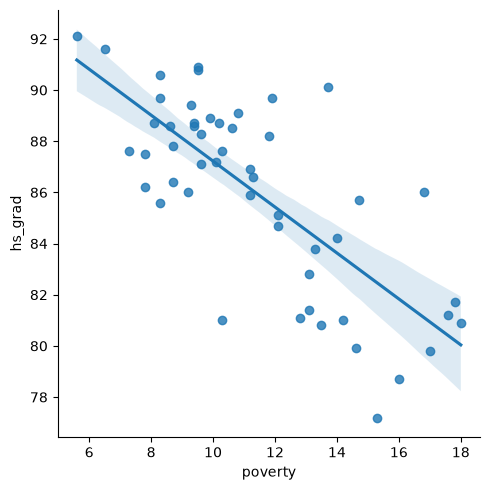

In [19]:
'''
Sarcina: aplicăm regresia liniară și verificăm cum sunt legate sărăcia (VD: poverty) și nivelul de educație (predictor, VI).
- Construim un scatter plot pentru a cunoaște caracterul variabilelor noastre. Vedem că se observă o dependență liniară.
- Mai mult, legătura este negativă.
- Dacă am calcula coeficientul de corelație, am obține r=-0.75.
'''
# Vom folosi seaborn (o bibliotecă de nivel mai înalt peste matplotlib). Pandas folosește de asemenea matplotlib, dar în formă pură.
# Seaborn are 2 grafice pentru regresie: lmplot și regplot.
# În cel mai simplu caz, ambele funcții construiesc diagrama de dispersie a variabilelor x și y, apoi dreapta de regresie rezultată și
# intervalul de încredere de 95% pentru această regresie: x~y.
# regplot are un subset al funcțiilor lui lmplot.

# Punem ";" ca să nu afișăm text inutil
sns.lmplot(x="poverty", y="hs_grad",data=df,fit_reg=True);

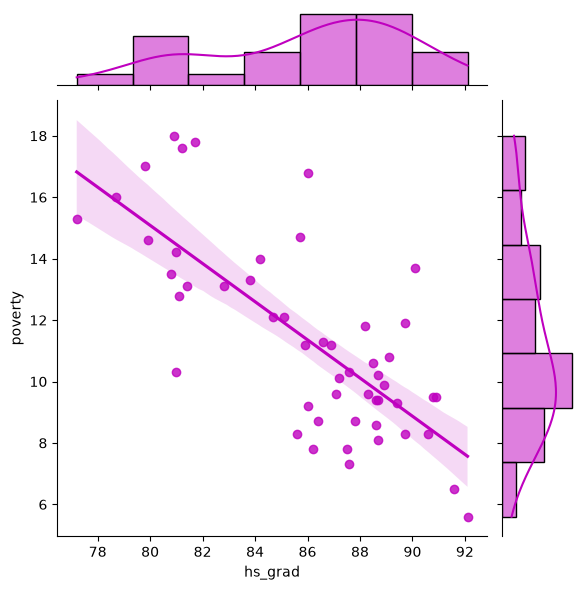

In [20]:
# Un exemplu de grafic și mai sugestiv
sns.jointplot(x='hs_grad', y='poverty', data=df, kind='reg', color='m');

Ce trebuie să găsim:

1. Construim modelul de regresie care explică legătura dintre variabilele noastre. În cazul nostru, aceasta va fi ecuația dreptei de regresie: $$\widehat{y}=b_{0}+b_{1}x$$
Pentru a construi acest model trebuie să calculăm coeficientul $b_0$ (intercept), care răspunde de locul în care dreapta noastră intersectează axa $y$, și coeficientul $b_1$, care răspunde de panta dreptei.
2. După ce am construit modelul, vrem să înțelegem cât de bine explică modelul comportamentul celor două variabile. Pentru aceasta găsim coeficientul de determinație $R^2$ și răspundem la întrebarea: ce % din dispersie este explicat de modelul nostru. Ipoteza noastră nulă:
$$H_0: b_1=0$$
3. Problema prognozării: cum putem prezice VD pe baza datelor VI.


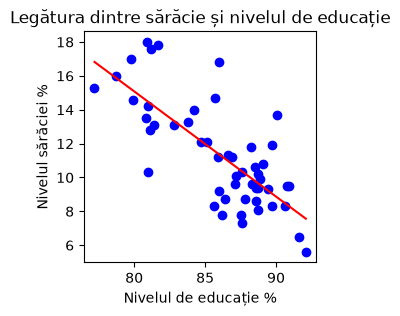

LinregressResult(slope=np.float64(-0.6212167177940106), intercept=np.float64(64.78096577010209), rvalue=np.float64(-0.7468582531582505), pvalue=np.float64(3.1088298103184175e-10), stderr=np.float64(0.0790164710017928), intercept_stderr=np.float64(6.802595178281202))

In [21]:
# Se poate rezolva așa
x=df["hs_grad"]
y=df["poverty"]
gradient, intercept, r_value, p_value, std_err = stats.linregress(x,y)
mn=np.min(x)
mx=np.max(x)
x1=np.linspace(mn,mx,500)
y1=gradient*x1+intercept

plt.plot(x,y,'ob') # Plasăm punctele
plt.plot(x1,y1,'-r') # Desenăm dreapta

plt.title("Legătura dintre sărăcie și nivelul de educație")
plt.xlabel("Nivelul de educație %")
plt.ylabel("Nivelul sărăciei %")

plt.show() # Desenăm graficul
stats.linregress (x, y)

<center><img src="../slides/week_3/week_3-25.png" title="slide 25" width="75%" height="75%"/></center>

In [22]:
# Dar se poate rezolva și așa. Bineînțeles, așa e mai bine))
OLS_model = ols('poverty ~ hs_grad', data=df).fit()
print(OLS_model.summary())

                            OLS Regression Results                            
Dep. Variable:                poverty   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     61.81
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           3.11e-10
Time:                        11:03:58   Log-Likelihood:                -108.74
No. Observations:                  51   AIC:                             221.5
Df Residuals:                      49   BIC:                             225.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     64.7810      6.803      9.523      0.0

Ne amintim că ipoteza nulă a fost formulată în limbajul analizei de regresie: $H_0: b_1=0$. Pentru verificarea acestei ipoteze se folosește testul t (t value din tabelul rezultatelor ols).

În tabelul obținut mai sus sunt afișate: eroarea standard (std err), valoarea testului t (t value) și nivelul de semnificație p ($P>|t|$).

Nivelul de semnificație p în acest caz este mult mai mic decât 0.05, ceea ce ne permite să respingem ipoteza nulă. Cu alte cuvinte, **am descoperit o legătură semnificativă statistic între cele două variabile ale noastre**.

De asemenea, putem observa că și în dreptul Intercept-ului sunt calculate eroarea standard, valoarea testului t și nivelul de semnificație p. Și în acest caz $p<0.05$. Aici se verifică ipoteza că interceptul este diferit de zero ($b_0 \ne 0$). În acest caz efectul nu este la fel de semnificativ ca în cazul precedent, dar totuși, **dacă presupunem existența unui stat în care procentul persoanelor cu studii medii este egal cu zero, ne așteptăm ca procentul sărăciei în acest stat să fie de 64%**.

După ce ne-am convins că legătura dintre variabilele noastre este semnificativă statistic, interpretăm valoarea coeficientului $b_1$: **la fiecare creștere cu 1% a locuitorilor statului cu studii medii, procentul sărăciei va scădea cu 0.62%**.

Valoarea coeficientului de determinație (R-squared) egală cu 0.558 înseamnă că **aproximativ 56% din variabilitatea variabilei noastre dependente este explicată de modelul nostru**. Nu este chiar atât de mult, deoarece nu ținem cont de influența multor factori.


Material suplimentar:

- [Articol](https://gigabaza.ru/doc/27078-pall.html) despre cum se calculează std err (în limba rusă)
- Merită să citiți [articolul](https://seaborn.pydata.org/tutorial/regression.html) despre vizualizarea regresiei de la Seaborn.

<center><img src="../slides/week_3/week_3-26.png" title="slide 26" width="50%" height="50%"/></center>

Acum trebuie să analizăm reziduurile. Vedem că pe alocuri reziduurile sunt pozitive, iar pe alocuri negative. Și, în general, variabilitatea reziduurilor se menține aproximativ aceeași pe toată direcția VI. Aceasta ne spune că cerința de homoscedasticitate este îndeplinită.

Studiind graficul qqplot, majoritatea reziduurilor se află pe o dreaptă, ceea ce ne vorbește despre normalitatea distribuției. Deși există câteva valori care iau valori extrem de mari. Câteva state ies din tabloul general.

**Bazându-ne pe aceste afirmații, putem avea încredere în modelul nostru**.

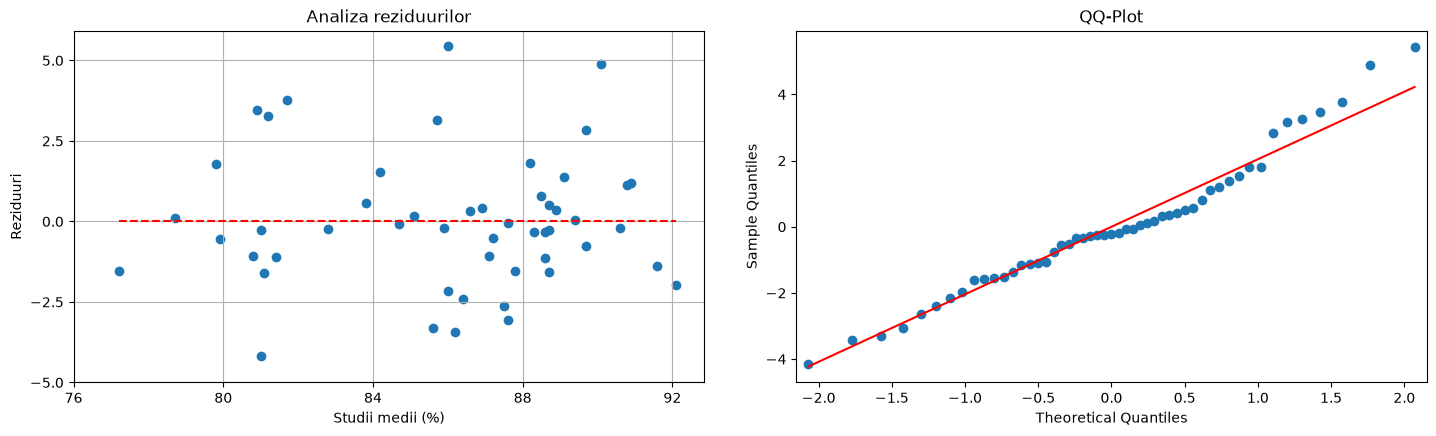

In [23]:
# obținem datele și calculăm coeficienții modelului de regresie
intercept, slope = ols(formula="poverty ~ hs_grad", data=df).fit().params
X = df['hs_grad']
Y = df['poverty']

# calculăm reziduurile — cât de departe este Y de modelul teoretic
residuals = Y - intercept - slope*X
x1=np.linspace(min(X),max(X),len(X))

# creăm graficele
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
# scatter plot
ax1.scatter(X,residuals)
ax1.plot(x1,[0]*len(x1),'--r')
# Q-Q plot
sm.qqplot(residuals, line='s', ax = ax2)

ax1.grid()
ax1.set_title('Analiza reziduurilor')
ax1.set_xlabel('Studii medii (%)')
ax1.set_ylabel('Reziduuri')
ax1.set_xticks(np.arange(76,93, step=4))
ax1.set_yticks(np.arange(-5,6, step=2.5))

ax2.set_title('QQ-Plot')

fig.tight_layout(pad=3.0)
plt.show()

In [24]:
'''
Un mod alternativ de a obține reziduurile cu ajutorul ols
'''
predicted = OLS_model.predict()  # valorile prezise
residual = OLS_model.resid # reziduurile

## 8.1. Problemă<a id="sec-8-1" name="sec-8-1"></a>

| 0           | Estimate | Std. error | t value | Pr(> t ) |
|-------------|----------|------------|---------|----------|
| (Intercept) | 58.7055  | 6.4524     | 9.10    | 0.0000   |
| Age         | 1.4632   | 0.1023     | 14.30   | 0.0000   |

În tabel sunt prezentate rezultatele unui studiu dedicat legăturii dintre tensiunea arterială și vârstă la persoanele cu vârsta între 45 și 70 de ani. Cercetătorii au aplicat analiza de regresie, unde drept variabilă dependentă a servit tensiunea arterială (pressure), iar drept variabilă independentă — vârsta pacienților (age). În acest studiu coeficientul de determinație s-a dovedit egal cu 0,95. Cum putem interpreta acest rezultat?

**Soluție:**
Conform rezultatelor obținute, ecuația de regresie va arăta astfel:
$$Pressure = 58.7 + 1.46*Age$$

- La fiecare schimbare pozitivă cu o unitate a variabilei independente (vârsta), valorile așteptate ale variabilei dependente (tensiunea) cresc cu 1,46.
- A fost descoperită o legătură pozitivă semnificativă statistic între variabilele studiate.




Să notăm că:
- <font color="green">Coeficientul de corelație dintre variabilele noastre este aproape de 1</font> — corect, deoarece coeficientul de determinație este pătratul coeficientului de corelație. $\sqrt{0.95}=0.97$, ceea ce este aproape de 1. Pe de altă parte, dacă extragem rădăcina, coeficientul de corelație ar putea fi și negativ.
- <font color="red">Coeficientul de corelație dintre variabilele noastre este aproape de -1</font> — în final, coeficientul de corelație nu poate fi negativ, deoarece avem o legătură pozitivă între variabile ($Age_{Estimate} = 1.4632 > 0$).
- <font color="red">Coeficientul de corelație dintre variabile este aproape de 1 sau de -1 (dar pentru un răspuns univoc nu sunt suficiente date)</font> — pornind de la punctul precedent, nu luăm în considerare un coeficient de corelație negativ.
- <font color="green">Aproape toate punctele se află pe dreapta de regresie</font> — corect, deoarece coeficienții de corelație și de determinație sunt aproape 1.
- <font color="green">95% din variabilitatea variabilei dependente (tensiunea) este explicată de modelul nostru</font> — exact acesta este sensul lui $R^2 = 0.95$.

# 9. Problema prognozării valorilor variabilei dependente<a id="sec-9" name="sec-9"></a>

<center><img src="../slides/week_3/week_3-27.png" title="slide 27" width="50%" height="50%"/></center>

Dreapta de regresie se mai numește uneori **linie de tendință**. Bazându-ne pe linia de tendință, putem prezice cu ce vor fi egale valorile VD la un anumit nivel al valorilor VI.

De exemplu, să marcăm pe dreaptă valoarea 95, care nu există în date, pentru a înțelege prognoza: ce nivel al sărăciei ar putea fi într-un stat cu 95% nivel de educație.
$$\widehat{y}=64.78 - 0.62*95=5.77$$

## 9.1. Observații<a id="sec-9-1" name="sec-9-1"></a>

- Faptul în sine al unei legături semnificative în analiza de regresie nu vorbește despre o relație cauză–efect.

# 10. Analiza de regresie cu mai multe variabile independente<a id="sec-10" name="sec-10"></a>

<center><img src="../slides/week_3/week_3-28.png" title="slide 28" width="50%" height="50%"/></center>

**Regresia multiplă** (*Multiple regression*) permite studierea influenței simultane a mai multor variabile independente (VI) asupra unei variabile dependente (VD).

Având VD ($Y$) — „indicatorul sărăciei”, notăm influența asupra ei a factorului „nivelul de educație al populației” (`hs_grad`), precum și a factorului „procentul populației albe din stat” (`white`)

\begin{equation*}
 \begin{cases}
   \widehat{y}=b_0+b_1X_1
   \\
   \widehat{y}=b_0+b_1X_1+b_2X_2
   \\
   ...
   \\
   \widehat{y}=b_0+b_1X_1+b_2X_2+...+b_nX_n
 \end{cases}
\end{equation*}

<center><img src="../slides/week_3/week_3-29.png" title="slide 29" width="50%" height="50%"/></center>

Folosind, de exemplu, 2 VI, concluzionăm că varianta optimă de aproximare a datelor noastre nu va mai fi o dreaptă, ci un plan întreg, pentru că acum lucrăm deja într-un spațiu tridimensional. Un astfel de plan reprezintă varianta cea mai reușită de descriere a legăturii din datele noastre. Acum **drept reziduuri nu va mai servi distanța până la dreaptă, ca în regresia cu o singură VI, ci distanța până la un plan întreg**. Și tot prin metoda celor mai mici pătrate (MCMMP) putem alege astfel de valori $b_0, b_1, b_2$ încât suma tuturor acestor erori, și anume a pătratelor distanțelor (unele puncte sunt sub plan, altele deasupra), să fie optimă în raport cu toate punctele.

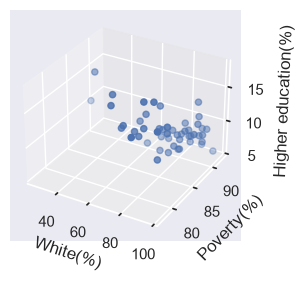

In [25]:
sns.set(style = "darkgrid")

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')

ax.set_xlabel("White(%)")
ax.set_ylabel("Poverty(%)")
ax.set_zlabel("Higher education(%)")

ax.scatter(df["white"], df["hs_grad"], df["poverty"])

plt.show()

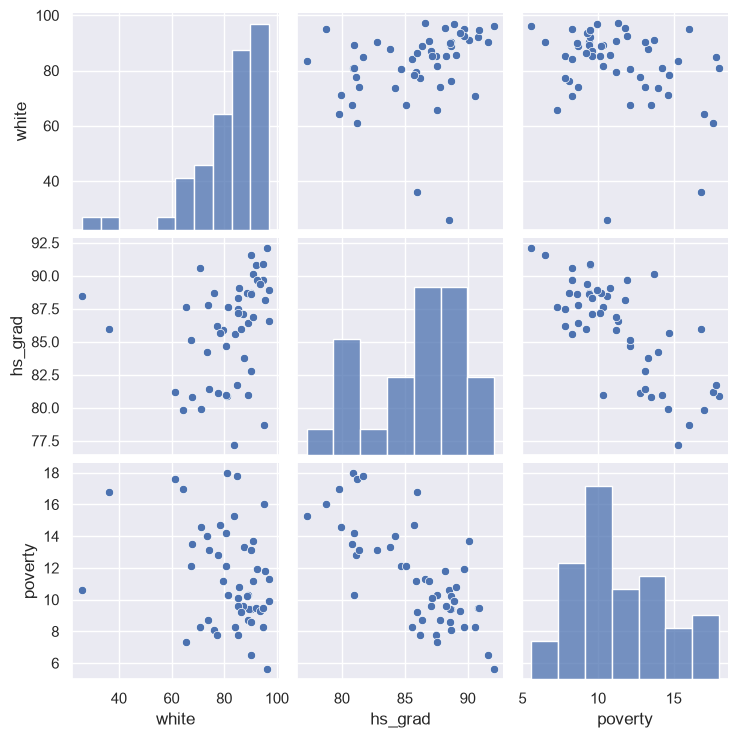

In [26]:
# Graficul scatter matrix arată legătura dintre parametri
# pd.plotting.scatter_matrix(df, alpha=0.5, figsize=(15, 5));

# Prin analogie cu scatter matrix din pandas, doar că cu ajutorul Seaborn
sns.pairplot(df[["white", "hs_grad","poverty"]]);

## 10.1. Cerințe față de date<a id="sec-10-1" name="sec-10-1"></a>

<center><img src="../slides/week_3/week_3-30.png" title="slide 30" width="50%" height="50%"/></center>

Greșeală de tipar pe slide: în loc de heteroscedasticitate — homoscedasticitatea datelor.
Includerea tuturor factorilor în analiză nu este întotdeauna corectă, dar pentru o analiză primară este potrivită.

**Multicoliniaritatea** (multicollinearity) — în econometrie (analiza de regresie) — existența unei dependențe liniare între variabilele explicative (factorii) modelului de regresie.

In [27]:
'''
Nu a ieșit cea mai sugestivă soluție vizuală. Totul din cauza interpretării magic command-ului %matplotlib
Dacă vă interesează, citiți suplimentar
'''
data = df

# Pentru a adăuga variabile, trebuie să însumăm câmpurile în formulă
lm = ols(formula='poverty ~ metro_res + white + hs_grad + female_house', data=data).fit()

Text(0.5, 0, 'poverty')

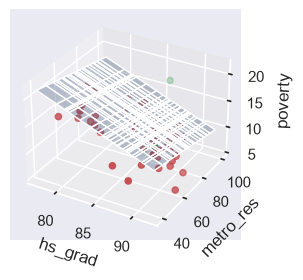

In [28]:
'''
Construim graficul doar pentru 2 predictori
'''
def f(x, y):
    return lm.params.Intercept + lm.params.hs_grad * x  + lm.params.metro_res * y

x = data.hs_grad.sort_values()
y = data.metro_res.sort_values()

X, Y = np.meshgrid(x, y)
Z = f(X, Y)

fig = plt.figure()
ax = plt.axes(projection='3d')
ax.plot_surface(X, Y, Z, alpha=0.3)
data_below_serf = data[data['poverty'] < f(data['hs_grad'], data['metro_res'])]
data_above_serf = data[data['poverty'] >= f(data['hs_grad'], data['metro_res'])]
ax.scatter(data_below_serf.hs_grad, data_below_serf.metro_res, data_below_serf.poverty, c='r', marker='o')
ax.scatter(data_above_serf.hs_grad, data_above_serf.metro_res, data_above_serf.poverty, c='g', marker='o')
ax.set_xlabel('hs_grad')
ax.set_ylabel('metro_res')
ax.set_zlabel('poverty')

In [29]:
lm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                poverty   R-squared:                       0.642
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     20.58
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           8.88e-10
Time:                        11:04:02   Log-Likelihood:                -103.39
No. Observations:                  51   AIC:                             216.8
Df Residuals:                      46   BIC:                             226.4
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       66.4765     12.590      5.280      0.000      41.134      91.819
metro_res       -0.0563      0.020     -2.881      0.006      -0.096      -0.017
white           -0.0481      0.033     -1.456      0.152      -0.115       0.018
hs_grad         -0.5547      0.105     -5.288      0.000      -0.766      -0.344
female_house     0.0505      0.243      0.208      0.836      -0.439       0.540
==============================================================================
Omnibus:                        3.254   Durbin-Watson:                   1.891
Prob(Omnibus):                  0.197   Jarque-Bera (JB):                3.043
Skew:                           0.585   Prob(JB):                        0.218
Kurtosis:                       2.750   Cond. No.                     6.50e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.5e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Să analizăm ce înseamnă fiecare element de aici.

În tabelul de mai sus există valoarea `Intercept`-ului și lista tuturor VI.
- Coloana 1 (`coef`) indică coeficienții calculați, care arată cel mai bine (prin metoda celor mai mici pătrate) legătura VD cu VI.
- Valoarea coeficientului `Intercept` = 66.4765 în cazul regresiei liniare simple este doar valoarea în care dreapta intersectează axa $y$. Dar în cazul nostru, al regresiei multiple, interpretarea este următoarea: cu cât ar fi egal procentul persoanelor care trăiesc în sărăcie, dacă presupunem că toate celelalte variabile sunt egale cu zero.
- În dreptul fiecărei variabile vedem: eroarea standard (`std err`), criteriul t (`t`) și nivelul de semnificație p (`P>|t|`).
- Cu ajutorul criteriului t verificăm, pentru fiecare coeficient, ipoteza că el diferă de zero. Dacă un coeficient ar fi egal cu zero, această variabilă nu ar influența VD-ul nostru.
- Să începem cu coeficientul „% persoanelor care locuiesc în zona metropolitană” (`metro_res`):
    - În primul rând, vedem că el este semnificativ statistic ($p=0.006<0.05$), adică are sens să-l interpretăm. Deci această variabilă este legată de VD-ul nostru.
    - Mai departe, vedem că coeficientul este negativ ($Estimate=-0.0563$). Deci procentul sărăciei este legat negativ de procentul persoanelor care locuiesc în zona metropolitană. Cu cât mai mulți oameni locuiesc în zona metropolitană, cu atât sărăcia este mai mică acolo. Foarte important: **-0.0563 înseamnă că, dacă am presupune că toate celelalte variabile nu se schimbă, sunt toate fixate, atunci la fiecare 1% de persoane care locuiesc în zona metropolitană, procentul persoanelor care trăiesc în sărăcie ar scădea cu 0.0563%**. Astfel, analiza de regresie ne permite **să excludem situația în care o VI influențează VD prin intermediul altei VI**.
- Să trecem la coeficientul „populației albe” (`white`). El este de asemenea negativ ($-0.0481$), adică legătura VD cu VI este negativă. Dar vedem că acest coeficient nu diferă semnificativ de zero ($p=0.152$), de aceea nu putem vorbi despre o legătură semnificativă între % populației albe și sărăcie.
- Coeficientul „studiilor medii” (`hs_grad`). Este cel mai mare în modul, $-0.5547$, și are o semnificație destul de ridicată, $p=0.000$, ceea ce ne permite cu siguranță să vorbim despre o legătură semnificativă statistic. Interpretare: **cu condiția ca toate celelalte variabile să rămână neschimbate, o schimbare cu 1% a persoanelor cu studii medii ar duce la o scădere așteptată a persoanelor care trăiesc sub pragul sărăciei cu 0.5547%**.
- Coeficientul gospodăriilor (`female_house`). Nivelul de semnificație p este foarte mare, ceea ce ne permite să nu luăm în considerare acest coeficient.

**$R^2$ ajustat** (*adjusted R-squared*) — coeficientul de determinație corectat. Se calculează la includerea în model a unor variabile independente (VI) suplimentare.

Să trecem la indicatorii globali de deasupra tabelului.
- `R-squared` ne arată cât de bine, în principiu, explică modelul nostru VD-ul. Ce parte din variabilitatea VD-ului este explicată de modelul nostru.
- `Adj. R-squared` ($R^2$ ajustat), cu alte cuvinte, face o corecție pentru numărul mare de VI.

# 11. Alegerea celui mai bun model<a id="sec-11" name="sec-11"></a>

Când construim un model de regresie, nu este deloc sigur că, cu cât am inclus mai multe variabile în analiză, cu atât rezultatul obținut este mai bun. Prin rezultat vom înțelege $R^2$, adică cât de bine explică modelul nostru variabilitatea variabilei dependente. Sau, altfel spus, cât de bine coincid valorile noastre prezise cu valorile reale.

<center><img src="../slides/week_3/week_3-32.png" title="slide 32" width="50%" height="50%"/></center>

Pe slide vedem variabila `female_house`, care corelează puternic cu toate celelalte. De aceea prezența acestei variabile nu doar că nu îmbunătățește modelul nostru, ci chiar îl înrăutățește.

array([[ 1.        , -0.34244157,  0.01811049, -0.20423477,  0.3000617 ],
       [-0.34244157,  1.        ,  0.23815607, -0.30852007, -0.75139437],
       [ 0.01811049,  0.23815607,  1.        , -0.74685825, -0.61186726],
       [-0.20423477, -0.30852007, -0.74685825,  1.        ,  0.52539698],
       [ 0.3000617 , -0.75139437, -0.61186726,  0.52539698,  1.        ]])

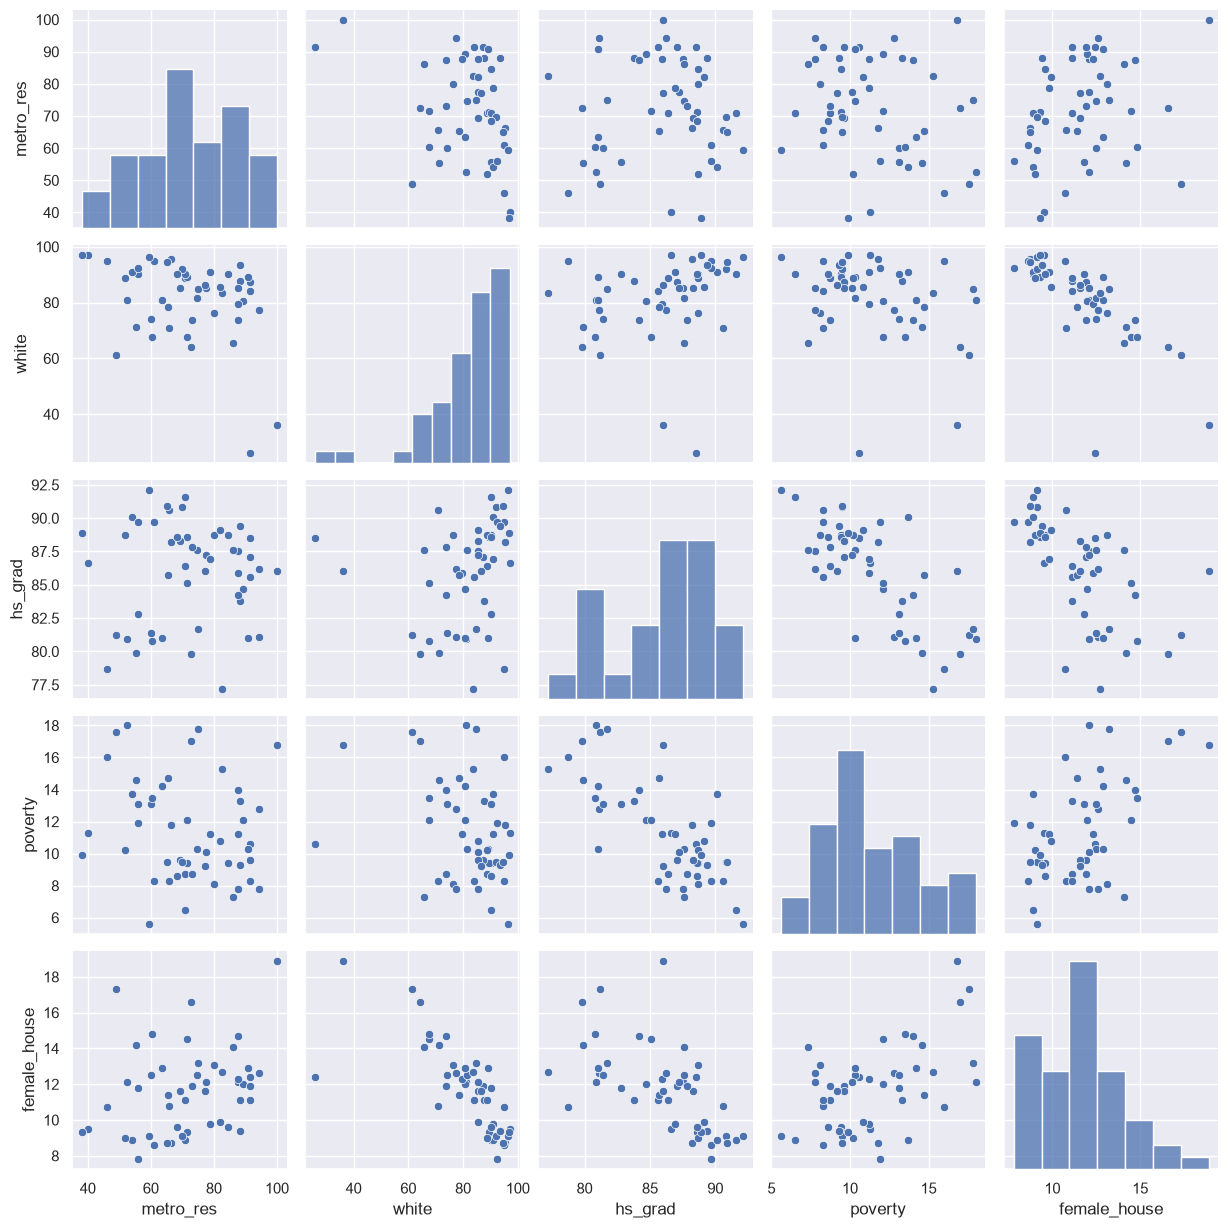

In [30]:
# Varianta prin Seaborn
p = sns.pairplot(df)
# Coeficienții de corelație
corr = df.corr(numeric_only=True).values
corr

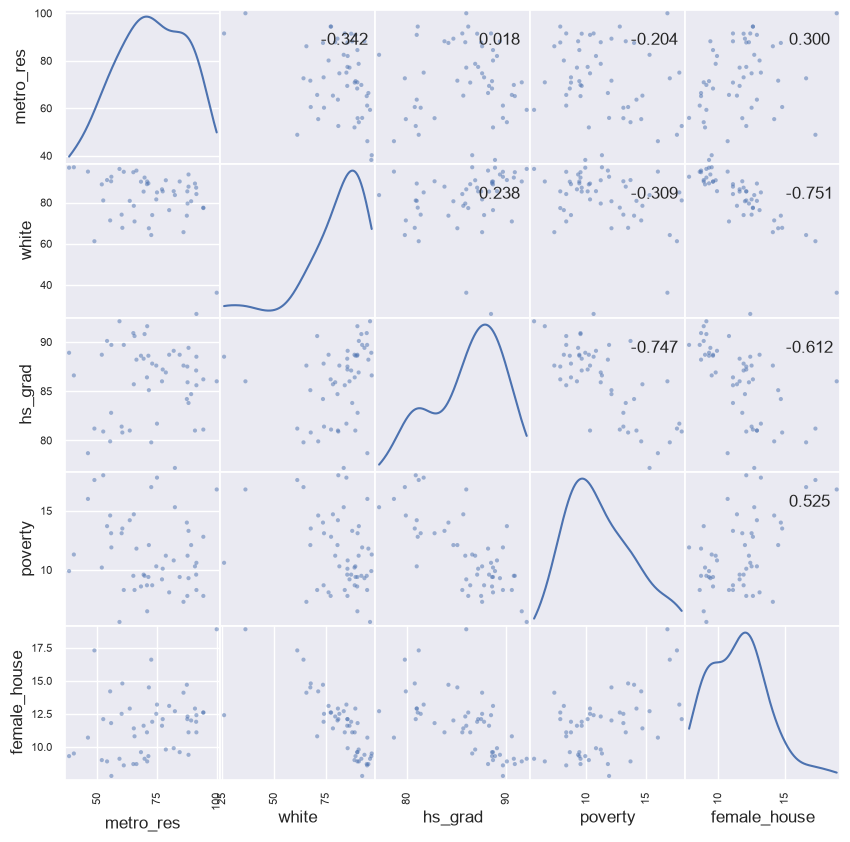

In [31]:
# Varianta alternativă prin matplotlib
axes = pd.plotting.scatter_matrix(df, figsize=(10,10), diagonal='kde', grid=True)
corr = df.corr(numeric_only=True).values
for i, j in zip(*np.triu_indices_from(axes, k=1)):
    axes[i, j].annotate("%.3f" %corr[i,j], (0.8, 0.8), xycoords='axes fraction', ha='center', va='center')
plt.show()

## 11.1. Alegerea modelului<a id="sec-11-1" name="sec-11-1"></a>

<center><img src="../slides/week_3/week_3-33.png" title="slide 33" width="75%" height="75%"/></center>

- Mai întâi construim modelul în care includem toate variabilele (rândul 1) și calculăm indicatorul „$R^2$ ajustat”.

Vom elimina pe rând coeficienții și vom urmări influența asupra indicatorului. **În analiza de regresie cantitatea nu înseamnă calitate — dacă o variabilă încurcă, este mai bine s-o eliminăm**.

- Eliminăm `female_house`. Indicatorul $R^2=0.62$ s-a îmbunătățit.
Și așa mai departe...

- După ce am ales modelul cu cei mai buni indicatori (fără `female_house`), încercăm din nou să eliminăm diverse variabile. În final, acest model este cel mai bun.

In [32]:
'''
Parcurgerea programatică a combinațiilor de VI
'''
# Găsim un astfel de set de caracteristici încât R-squared să fie maxim
feats = {'metro_res', 'white', 'hs_grad', 'female_house'}

# Parcurgem recursiv toate combinațiile de variabile
def brute_force(params: set, formula: str, result: set) -> str:
    if not params:
        result.add(formula.lstrip('+ '))
        return
    else:
        new_params = params.copy()
        for el in params:
            new_params.remove(el)

            brute_force(new_params, formula + ' + ' + el, result)
            brute_force(new_params, formula, result)

res = set()
brute_force(feats, '', res)
res.remove('')

# Acum calculăm Adjusted R-Square pentru fiecare combinație și îl afișăm pe ecran
for formula in res:
    lm = ols(formula='poverty ~ ' + formula, data=df).fit()
    print(f'{lm.rsquared_adj:.2}', formula)

0.022 metro_res
0.17 metro_res + white
0.61 female_house + hs_grad + metro_res + white
0.4 female_house + metro_res
0.26 female_house
0.6 female_house + hs_grad + metro_res
0.55 female_house + hs_grad
0.62 hs_grad + metro_res + white
0.55 hs_grad
0.39 female_house + metro_res + white
0.56 hs_grad + white
0.077 white
0.58 hs_grad + metro_res
0.26 female_house + white
0.55 female_house + hs_grad + white


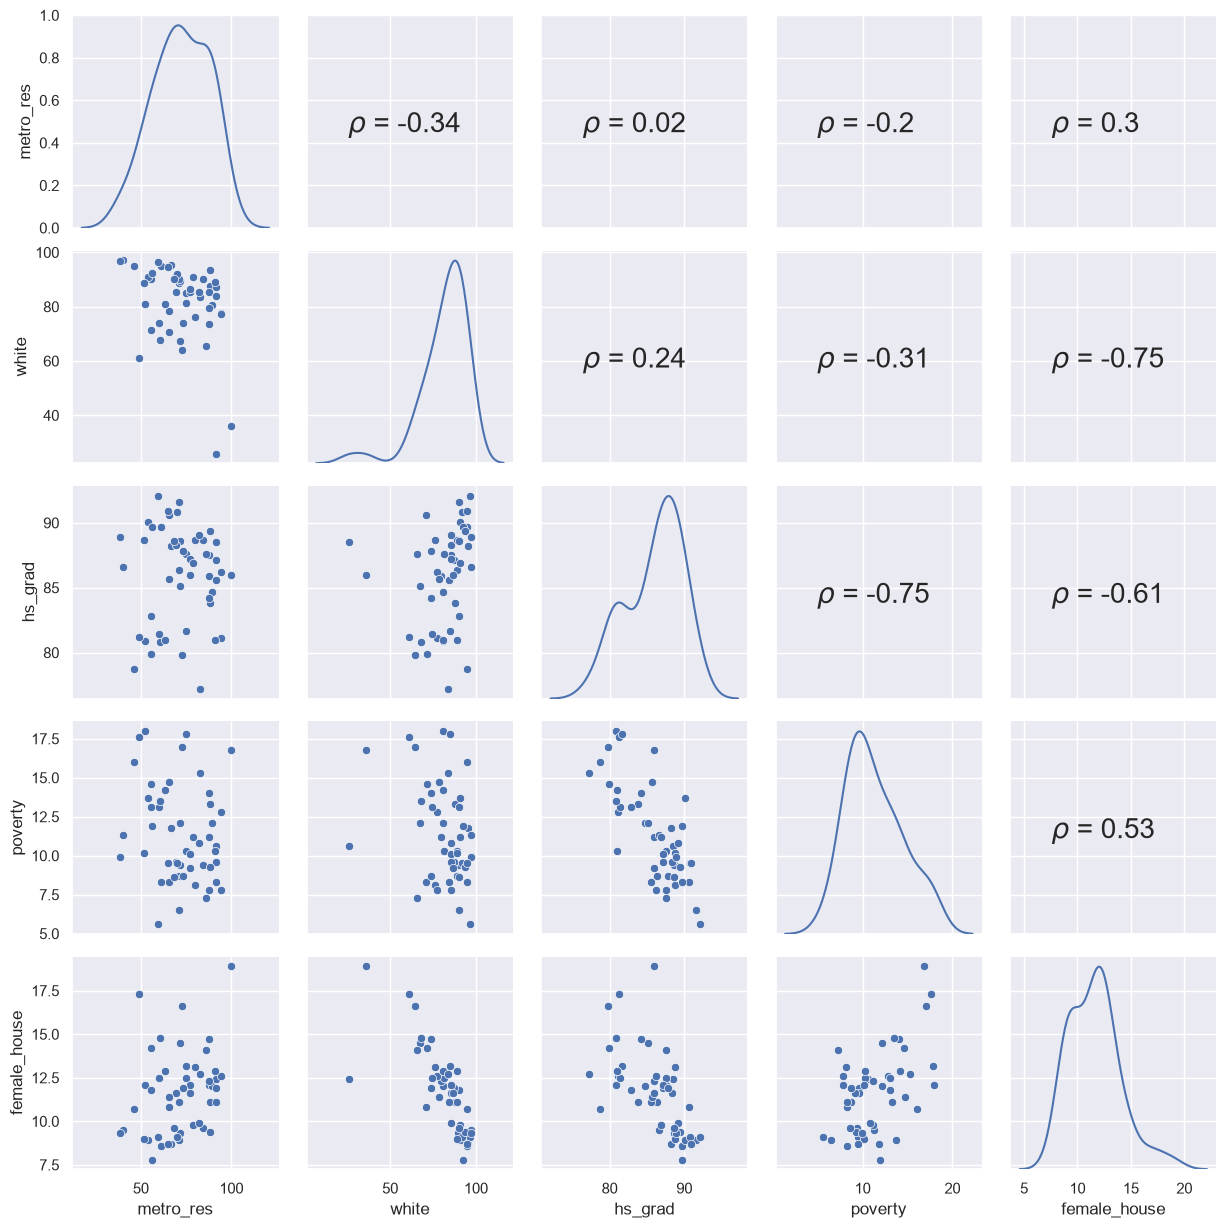

In [33]:
# Function to calculate correlation coefficient between two arrays
def corr(x, y, **kwargs):
    # Calculate the value
    coef = np.corrcoef(x, y)[0][1]
    # Make the label
    label = r'$\rho$ = ' + str(round(coef, 2))
    # Add the label to the plot
    ax = plt.gca()
    ax.annotate(label, xy = (0.2, 0.45), size = 20, xycoords = ax.transAxes)

g = sns.PairGrid(df, diag_sharey=False)
# g.map_upper(sns.scatterplot)
g.map_upper(corr)
g.map_lower(sns.scatterplot)
g.map_diag(sns.kdeplot)

Revenind la analiză, să vedem cum interacționează, în principiu, VI noastre între ele.
- Să luăm `white` și `hs_grad`. Aceste VI sunt foarte slab legate între ele și **acesta este un indicator bun pentru model: când fiecare VI este legată de VD, dar în același timp VI nu corelează puternic între ele.**
- `metro_res` și `hs_grad` practic nu corelează deloc între ele, dar fiecare în parte este destul de bine legată de VD-ul nostru.
- `metro_res` și `white` ($\rho = -0.34$) corelează între ele, dar am văzut anterior că **includerea ambelor variabile în model nu înrăutățește situația**.

In [34]:
# Modelul final
final_model = ols(formula='poverty ~ white + metro_res + hs_grad', data=df).fit()
final_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                poverty   R-squared:                       0.641
Model:                            OLS   Adj. R-squared:                  0.618
Method:                 Least Squares   F-statistic:                     28.00
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           1.55e-10
Time:                        11:04:14   Log-Likelihood:                -103.41
No. Observations:                  51   AIC:                             214.8
Df Residuals:                      47   BIC:                             222.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     68.7220      6.389     10.756      0.000      55.869      81.575
white         -0.0533      0.021     -2.483      0.017      -0.097      -0.010
metro_res     -0.0555      0.019     -2.926      0.005      -0.094      -0.017
hs_grad       -0.5697      0.075     -7.569      0.000      -0.721      -0.418
==============================================================================
Omnibus:                        3.479   Durbin-Watson:                   1.900
Prob(Omnibus):                  0.176   Jarque-Bera (JB):                3.230
Skew:                           0.607   Prob(JB):                        0.199
Kurtosis:                       2.787   Cond. No.                     3.32e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.32e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Excluzând din analiză variabila `female_house`, care corela foarte puternic cu celelalte VI:
- Am mărit $R^2$;
- VI `white` a devenit și ea legată semnificativ ($p=0.017$) de VD. Înainte era $p=0.152$.

VD-ul nostru `poverty` este descris de modelul:
$$\widehat{y}=68.722-0.0533*\text{white}-0.0555*\text{metro_res}-0.5697*\text{hs_grad}$$

<center><img src="../slides/week_3/week_3-35.png" title="slide 35" width="75%" height="75%"/></center>

Și, în final, să ne convingem că reziduurile se comportă normal.
- Distribuția lor este destul de simetrică.
- Variabilitatea este destul de constantă.
- Construind qq-plot-ul, ne putem convinge, în majoritatea cazurilor, de normalitatea distribuției.

## 11.2. Observații<a id="sec-11-2" name="sec-11-2"></a>
1. În analiza de regresie (mai ales în cea multiplă) cantitatea nu înseamnă întotdeauna calitate. Excluderea variabilelor care corelează puternic cu altele va îmbunătăți doar indicatorii modelului.
2. „Care este avantajul acestei metode față de corelație?” Doar am fi putut construi matricea tuturor corelațiilor posibile și să încheiem analiza.
    - Manipulările cu corelațiile sunt o poveste groaznică. Nu le folosiți niciodată. Apare pericolul comparațiilor multiple. Revenim la corecția Bonferroni și la comparațiile multiple din analiza dispersională.
3. Analiza de regresie și coeficienții ei ne dau o informație mai interesantă despre legătura dintre VD-ul nostru și un anumit predictor. Nu este doar corelația lor. Este cât de puternic sunt legate între ele, cu condiția că am ținut cont de toate celelalte variabile și acestea nu se schimbă. În cazul analizei de regresie nu vom obține o legătură care se datorează unei a treia variabile.

# 12. Clasificarea: regresia logistică și analiza cluster<a id="sec-12" name="sec-12"></a>
## 12.1. Regresia logistică<a id="sec-12-1" name="sec-12-1"></a>

<center><img src="../slides/week_3/week_3-39.png" title="slide 39" width="50%" height="50%"/></center>

**Regresia logistică** sau **modelul logit** (*logit model*) este un model statistic folosit pentru prognozarea probabilității apariției unui eveniment prin compararea lui cu curba logistică. Această regresie dă răspunsul sub forma probabilității unui eveniment binar (1 sau 0).

### 12.1.1. Exemplu<a id="sec-12-1-1" name="sec-12-1-1"></a>

VD `admin` — reușita admiterii candidatului la universitate.
Predictorul (VI) `mark` — nota medie la școală.

Interpretarea aici va fi foarte asemănătoare cu cea din cazul regresiei liniare. Dacă coeficientul nostru pentru VI ($1.0511$) diferă semnificativ statistic de zero ($0.0004<0.05$), aceasta înseamnă că la fiecare creștere cu o unitate a valorii VI, probabilitatea ca candidatul să susțină examenul va crește.

Regresia logistică permite să facem prognoze.

## 12.2. Analiza cluster<a id="sec-12-2" name="sec-12-2"></a>

**Analiza cluster** (*cluster analysis*) este o procedură statistică multidimensională care colectează date ce conțin informații despre un eșantion de obiecte și apoi ordonează obiectele în grupuri relativ omogene. Problema clusterizării ține de prelucrarea statistică, precum și de clasa largă a problemelor de învățare nesupervizată.

<center><img src="../slides/week_3/week_3-37.png" title="slide 37" width="50%" height="50%"/></center>

Întrebarea principală: putem oare evidenția un grup din observații?

AC încearcă să găsească observațiile asemănătoare și, în același timp, să le separe pe cele diferite. Apoi, după reducerea dimensionalității, putem lucra cu un număr mai mic de elemente.

Analiza ierarhică.